# Ticker Agent System

A WIP of the ticker agent system.

## 0. Config

In [1]:
from collections import Counter, defaultdict
from pathlib import Path
import json
import math
import re
import warnings

warnings.filterwarnings("ignore", message=".*penalty.*deprecated.*")
warnings.filterwarnings("ignore", message=".*Inconsistent values.*")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spacy
import yfinance as yf
from datasets import load_dataset
from scipy.sparse import coo_matrix
from sklearn.cluster import AgglomerativeClustering
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

TICKER = "AAPL"
PANEL = ["AAPL", "XOM", "JPM", "PFE", "F", "CAT"]
RANDOM_STATE = 42
FAMILY_COLORS = {"c": "#4f81bd", "e": "#d28b36", "m": "#8c8c8c"}
NEG = "#c0504d"

REPO_ROOT = Path.cwd().parent
assert (REPO_ROOT / "pyproject.toml").exists(), "run this notebook from notebooks/"
DATA_PROCESSED = REPO_ROOT / "data" / "processed"
LLM_CACHE = REPO_ROOT / "data" / "llm_cache"
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
LLM_CACHE.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 170)


def banner(title):
    print(f"\n{'=' * 78}\n{title}\n{'=' * 78}")


def mcnemar_p(a, b):
    n01 = int((~a & b).sum())
    n10 = int((a & ~b).sum())
    n = n01 + n10
    if n == 0:
        return 1.0
    k = min(n01, n10)
    p = sum(math.comb(n, i) for i in range(k + 1)) / 2 ** n
    return min(1.0, 2 * p)


banner(f"L0 CONFIG  ticker={TICKER}  panel={PANEL}  weekly bins, next-week direction label  the L7 arms below are pre-registered before the agent loop runs")

C:\Users\18587\Documents\Projects\University of San Diego\AAI-520 Final Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



L0 CONFIG  ticker=AAPL  panel=['AAPL', 'XOM', 'JPM', 'PFE', 'F', 'CAT']  weekly bins, next-week direction label  the L7 arms below are pre-registered before the agent loop runs


## 1. Corpus funnel - prompt-chain stage 1 (ingest) and stage 2 (preprocess)

In [2]:
banner("L1.1 INGEST · spine step 1/7 - one decade of financial headlines, one row per headline (prompt-chain stage 1/5)")
nifty = load_dataset("raeidsaqur/NIFTY", trust_remote_code=True)
rows = []
for split in ["train", "valid", "test"]:
    fr = nifty[split].to_pandas()[["date", "news"]]
    for d, news in zip(pd.to_datetime(fr["date"]), fr["news"]):
        for h in str(news).split("\n"):
            if h.strip():
                rows.append((d, split, h.strip()))
heads = pd.DataFrame(rows, columns=["date", "split", "headline"])
heads["week"] = heads["date"].dt.to_period("W-FRI")
print(f"{len(heads):,} headlines | {heads['week'].nunique()} weekly bins | {heads['date'].min().date()} to {heads['date'].max().date()}")
heads[["date", "headline"]].head(3)


L1.1 INGEST · spine step 1/7 - one decade of financial headlines, one row per headline (prompt-chain stage 1/5)


436,564 headlines | 560 weekly bins | 2010-01-06 to 2020-09-21


,date,headline
0,2010-01-06,China Officials Likely Knew of Bad Milk
1,2010-01-06,Sony's CEO on Strategy in 3-D Technology
2,2010-01-06,Copper Settles at 16-Month High



L1.2 WIRE BOILERPLATE · spine step 1/7 - which headlines are publisher formatting rather than news? trigrams repeating in >= 150 headlines flag them (prompt-chain stage 2/5: preprocess)


917 boilerplate trigrams | 30.2% of headlines flagged


,boilerplate trigram,headlines flagged via
0,net asset value,40426
1,research and markets,21077
2,reg db trackers,18109
3,etf net asset,17274
4,db trackers msci,6278
5,index etf net,5577
6,reg cs etf,4833
7,cs etf ie,4725
8,etf ie on,4610
9,to present at,4495



L1.3 DEDUP - identical normalized text within a week is one story, not two


289,147 unique headlines remain (66.2% of raw)
verdict: 30% of the decade is wire boilerplate; 289,147 headlines carry actual news


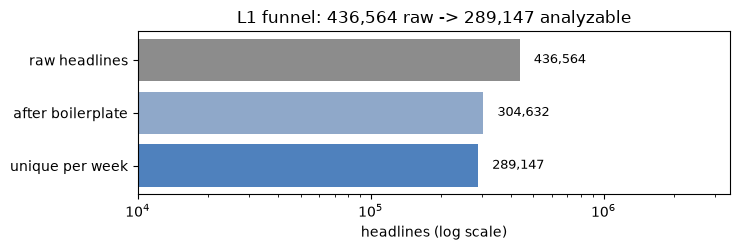

In [3]:
banner("L1.2 WIRE BOILERPLATE · spine step 1/7 - which headlines are publisher formatting rather than news? trigrams repeating in >= 150 headlines flag them (prompt-chain stage 2/5: preprocess)")
TOKEN = re.compile(r"[a-z]{2,}")
heads["tokens"] = heads["headline"].str.lower().map(lambda s: TOKEN.findall(s))
tpl = CountVectorizer(analyzer=lambda toks: [" ".join(toks[i:i + 3]) for i in range(len(toks) - 2)],
                      ngram_range=(1, 1), min_df=150, max_features=30000).fit(heads["tokens"])
tpl_grams = set(tpl.get_feature_names_out())
heads["is_template"] = heads["tokens"].map(
    lambda t: any(" ".join(t[i:i + 3]) in tpl_grams for i in range(len(t) - 2)))
tpl_counts = Counter()
for toks, flag in zip(heads["tokens"], heads["is_template"]):
    if flag:
        for i in range(len(toks) - 2):
            g = " ".join(toks[i:i + 3])
            if g in tpl_grams:
                tpl_counts[g] += 1
print(f"{len(tpl_grams):,} boilerplate trigrams | {heads['is_template'].mean():.1%} of headlines flagged")
top_tpl = tpl_counts.most_common(10)
display(pd.DataFrame({"boilerplate trigram": [g for g, _ in top_tpl],
                      "headlines flagged via": [c for _, c in top_tpl]}))

banner("L1.3 DEDUP - identical normalized text within a week is one story, not two")
heads["norm"] = heads["tokens"].map(" ".join)
clean = heads[~heads["is_template"]].drop_duplicates(subset=["week", "norm"]).reset_index(drop=True)
print(f"{len(clean):,} unique headlines remain ({len(clean) / len(heads):.1%} of raw)")
print(f"verdict: {heads['is_template'].mean():.0%} of the decade is wire boilerplate; {len(clean):,} headlines carry actual news")

fig, ax = plt.subplots(figsize=(7.5, 2.6))
stages = ["raw headlines", "after boilerplate", "unique per week"]
counts = [len(heads), int((~heads["is_template"]).sum()), len(clean)]
bars = ax.barh(stages[::-1], counts[::-1], color=["#4f81bd", "#8fa8c9", "#8c8c8c"])
ax.set_xscale("log")
for b, c in zip(bars, counts[::-1]):
    ax.text(c * 1.15, b.get_y() + b.get_height() / 2, f"{c:,}", va="center", fontsize=9)
ax.set_xlim(1e4, len(heads) * 8)
ax.set_xlabel("headlines (log scale)")
ax.set_title(f"L1 funnel: {len(heads):,} raw -> {len(clean):,} analyzable")
plt.tight_layout()
plt.show()

## 2. Term extraction and the shared theme family - prompt-chain stage 4 (extract)

In [4]:
banner("L2.1 VOCABULARY · spine step 2/7 - one pass reads every headline and records its words, lemma-normalized, plus named entities (prompt-chain stage 4/5: extract)")
nlp = spacy.load("en_core_web_sm", disable=["parser"])
MONTHS = {"january", "february", "march", "april", "may", "june", "july", "august", "september",
          "october", "november", "december", "jan", "feb", "mar", "apr", "jun", "jul", "aug",
          "sep", "oct", "nov", "dec"}
STOP_EXTRA = MONTHS | {
    "plc", "inc", "ltd", "corp", "nv", "sa", "co", "company", "companies", "group",
    "holding", "holdings", "trust", "fund", "funds", "update", "alert", "research",
    "mln", "pct", "bn", "tn", "vs", "qtr", "nr", "gbx", "usd", "gbp", "cny", "yen",
    "bln", "mth", "wk", "yr", "table", "text", "reuters", "afp", "nyse", "nasdaq",
}
SPACY_STOP = nlp.Defaults.stop_words
ENTITY_LABELS = {"ORG", "GPE", "PRODUCT", "NORP", "LAW", "EVENT", "FAC"}

concept_sets, entity_sets, week_of = [], [], []
cw, ew = defaultdict(list), defaultdict(list)
surf = defaultdict(Counter)
occ_total = Counter()
edge_occ = defaultdict(Counter)
global_edge = Counter()

for start in range(0, len(clean), 40000):
    batch = clean.iloc[start:start + 40000]
    for (_, row), docy in zip(batch.iterrows(), nlp.pipe(batch["headline"], batch_size=1000)):
        toks = [t for t in docy if not t.is_space]
        ntok = len(toks)
        ws = [t.lower_ for t in toks]
        global_edge[("F", " ".join(ws[:2]))] += 1
        global_edge[("F", " ".join(ws[:3]))] += 1
        global_edge[("L", " ".join(ws[-2:]))] += 1
        global_edge[("L", " ".join(ws[-3:]))] += 1

        def rec(store, term, surface, i):
            store[term].append(row["week"])
            surf[term][surface] += 1
            occ_total[term] += 1
            if i < 2:
                edge_occ[term][("F", " ".join(ws[:2]))] += 1
                edge_occ[term][("F", " ".join(ws[:3]))] += 1
            elif i >= ntok - 2:
                edge_occ[term][("L", " ".join(ws[-2:]))] += 1
                edge_occ[term][("L", " ".join(ws[-3:]))] += 1

        cset, eset = set(), set()
        for i, t in enumerate(toks):
            lem = t.lemma_.lower()
            if t.pos_ == "NOUN" and t.is_alpha and len(lem) >= 3 and lem not in STOP_EXTRA and lem not in SPACY_STOP:
                cset.add(lem)
                rec(cw, lem, t.lower_, i)
            if i + 1 < len(toks):
                t2 = toks[i + 1]
                lem2 = t2.lemma_.lower()
                if (t.pos_ in ("NOUN", "ADJ") and t2.pos_ == "NOUN" and t.is_alpha and t2.is_alpha
                        and len(lem) >= 3 and len(lem2) >= 3
                        and lem not in STOP_EXTRA and lem2 not in STOP_EXTRA
                        and lem not in SPACY_STOP and lem2 not in SPACY_STOP):
                    cset.add(lem + " " + lem2)
                    rec(cw, lem + " " + lem2, t.lower_ + " " + t2.lower_, i + 1)
        for ent in docy.ents:
            if ent.label_ not in ENTITY_LABELS:
                continue
            name = re.sub(r"\s+", " ", re.sub(r"[^a-z ]", "", ent.text.lower())).strip()
            if len(name) >= 3 and name not in STOP_EXTRA and not name.isdigit():
                eset.add(name)
                rec(ew, name, ent.text.lower(), ent.start)
        concept_sets.append(frozenset(cset))
        entity_sets.append(frozenset(eset))
        week_of.append(row["week"])
    print(f"   spaCy pass: {min(start + 40000, len(clean)):,}/{len(clean):,}")
print(f"{len(cw):,} concept terms | {len(ew):,} entity terms")


L2.1 VOCABULARY · spine step 2/7 - one pass reads every headline and records its words, lemma-normalized, plus named entities (prompt-chain stage 4/5: extract)


   spaCy pass: 40,000/289,147


   spaCy pass: 80,000/289,147


   spaCy pass: 120,000/289,147


   spaCy pass: 160,000/289,147


   spaCy pass: 200,000/289,147


   spaCy pass: 240,000/289,147


   spaCy pass: 280,000/289,147


   spaCy pass: 289,147/289,147
55,630 concept terms | 142,242 entity terms


In [5]:
banner("L2.2 WIRE RESIDUE - words that appear almost only inside repeated wire phrases are deleted from the vocabulary")
tpl_edge = {k for k, c in global_edge.items() if c >= 150}
artifact = {}
for term, grams in edge_occ.items():
    tot = occ_total[term]
    if tot >= 150 and sum(c for k, c in grams.items() if k in tpl_edge) / tot >= 0.5:
        artifact[term] = tot
ex_rows = []
for term, tot in sorted(artifact.items(), key=lambda kv: -kv[1])[:8]:
    ex = clean.loc[clean["headline"].str.lower().str.contains(r"\b" + re.escape(term.split()[0]), regex=True), "headline"].head(1)
    ex_rows.append({"term": term, "occurrences": tot, "example": ex.iloc[0][:70] if len(ex) else ""})
display(pd.DataFrame(ex_rows))
print(f"{len(artifact)} terms flagged as wire-format artifacts and excluded from mining")

banner("L2.3 BURSTINESS - vocabulary must appear in >= 20 weeks and in bursts; a word ticking at a constant rate is a feed artifact, not news")
N_WEEKS = heads["week"].nunique()


def burst_ok(wlist):
    per = Counter(wlist)
    mu = len(wlist) / N_WEEKS
    var = (np.array(list(per.values()), float) ** 2).sum() / N_WEEKS - mu ** 2
    return len(per) >= 20 and (var / mu if mu > 0 else 0) >= 1.2


banner("L2.4 THINGS vs MARKET PROCESS - keep a word only if it names a thing in the world (oil, vaccine, store) rather than market process (profit, outlook, prices); vector margin > 0.25 or lexicon")
md_vec = spacy.load("en_core_web_md", disable=["tagger", "parser", "ner", "lemmatizer", "attribute_ruler"])
CONCEPT_SEEDS = """oil copper gold silver gas coal iron ore steel aluminum wheat corn coffee cotton
gasoline diesel uranium lithium ethanol phone smartphone device tablet gadget chip semiconductor
computer laptop internet broadband wireless network satellite cloud software app card camera
screen television media film game car truck vehicle airline plane ship rail freight shipping
logistics drug medicine vaccine hospital clinic biotech store supermarket hotel restaurant
farm mine drill refinery pipeline power solar wind electricity battery robot robotics drone
home house building factory machine tool food beer tobacco advertising telecom""".split()
MARKET_SEEDS = """profit loss revenue earnings price prices pricing rating ratings outlook
forecast estimate target jobs job employment sector service services market markets
stock stocks share shares bond bonds yield yields rate rates dollar euro yen yuan franc
inflation debt growth recession risk value index benchmark investor fund portfolio
dividend capital liquidity credit loan merger acquisition ipo trade tariff tax budget
deficit gdp payroll spending stimulus policy demand supply
cut cuts unit buy sell debut discount deal deals stake bid offer""".split()
LEXICON = {"supply chain", "credit card", "big data", "smart home", "internet of things",
           "social media", "e-commerce", "mobile phone", "cell phone", "electric vehicle",
           "electric car", "renewable energy", "wind farm", "solar power", "crude oil",
           "oil price", "gold price", "copper price", "natural gas", "shale oil",
           "oil", "oil spill", "barrel"}
Sv = np.array([md_vec(w).vector for w in CONCEPT_SEEDS])
Sv = Sv[np.linalg.norm(Sv, axis=1) > 0]
Mv = np.array([md_vec(w).vector for w in MARKET_SEEDS])
Mv = Mv[np.linalg.norm(Mv, axis=1) > 0]
Sv /= np.linalg.norm(Sv, axis=1, keepdims=True)
Mv /= np.linalg.norm(Mv, axis=1, keepdims=True)


def vec_margin(term):
    v = md_vec(term).vector
    if not v.any():
        return None
    v = v / np.linalg.norm(v)
    return float(np.sort(Sv @ v)[::-1][:3].mean() - np.sort(Mv @ v)[::-1][:3].mean())


cand_c = [t for t in cw
          if (len(cw[t]) >= (25 if t in LEXICON else 80)) and burst_ok(cw[t]) and t not in artifact]
cand_c.sort(key=lambda t: -len(cw[t]))
cand_e = [t for t in ew if len(ew[t]) >= 60 and burst_ok(ew[t]) and t not in artifact]
cand_e.sort(key=lambda t: -len(ew[t]))
margins = {t: vec_margin(t) for t in cand_c}
kept_c = [t for t in cand_c if t in LEXICON or (margins[t] is not None and margins[t] > 0.25)]
verdicts = pd.DataFrame([
    {"term": t, "margin": round(margins[t], 3) if margins[t] is not None else None,
     "admitted": bool(t in LEXICON or (margins[t] is not None and margins[t] > 0.25))}
    for t in cand_c[:30]])
display(verdicts)
print(f"concept candidates {len(cand_c)} -> kept {len(kept_c)} | entity candidates {len(cand_e)}")


L2.2 WIRE RESIDUE - words that appear almost only inside repeated wire phrases are deleted from the vocabulary


,term,occurrences,example
0,source,1605,China major fuel stocks up 2.4 pct in Dec - source
1,fitch,1228,Fitch: U.S. CMBS Delinquencies up 42bps; Peak Not Until 2012
2,oil price,1016,"European shares rise 0.6 pct; oils, miners strong"
3,markets,956,South Korean markets at 0500 GMT
4,forexeuro,914,
5,analysis,873,ANALYSIS-Bomber's betrayal shows spy challenge for West
6,forexdollar,825,
7,european share,617,European Stocks Close Flat


39 terms flagged as wire-format artifacts and excluded from mining

L2.3 BURSTINESS - vocabulary must appear in >= 20 weeks and in bursts; a word ticking at a constant rate is a feed artifact, not news

L2.4 THINGS vs MARKET PROCESS - keep a word only if it names a thing in the world (oil, vaccine, store) rather than market process (profit, outlook, prices); vector margin > 0.25 or lexicon


,term,margin,admitted
0,share,-0.427,False
1,stock,-0.589,False
2,bank,-0.107,False
3,market,-0.367,False
4,profit,-0.427,False
5,price,-0.191,False
6,sale,-0.063,False
7,rate,-0.290,False
8,investor,-0.427,False
9,year,-0.114,False


concept candidates 798 -> kept 68 | entity candidates 260


In [6]:
banner("L2.5 INDUSTRY FAMILY · spine step 2/7 - group the kept vocabulary into synonym themes (oil/crude/fuel become one theme); this is the GENERIC baseline, not company-specific")


def cluster(pool, sets, weeks_list):
    idx = {t: i for i, t in enumerate(pool)}
    r, c = [], []
    for hi, fs in enumerate(sets):
        for t in fs:
            j = idx.get(t)
            if j is not None:
                r.append(hi)
                c.append(j)
    X = coo_matrix((np.ones(len(r)), (r, c)), shape=(len(sets), len(pool))).tocsr()
    N = X.shape[0]
    co = (X.T @ X).toarray().astype(float)
    px = np.diag(co) / N
    with np.errstate(divide="ignore", invalid="ignore"):
        npmi = np.log((co / N) / (px[:, None] * px[None, :])) / (-np.log(co / N))
    npmi[co == 0] = -1.0
    np.fill_diagonal(npmi, 1.0)
    dist = np.clip(1.0 - npmi, 0, 2)
    np.fill_diagonal(dist, 0.0)
    dist = (dist + dist.T) / 2
    cl = AgglomerativeClustering(n_clusters=None, distance_threshold=0.75,
                                 metric="precomputed", linkage="average").fit(dist)
    groups = defaultdict(list)
    for t, cid in zip(pool, cl.labels_):
        groups[int(cid)].append(t)
    tot = {t: len(weeks_list[t]) for t in pool}
    out = []
    for members in groups.values():
        if len(members) == 1 and members[0] not in LEXICON:
            continue
        members.sort(key=lambda t: -tot[t])
        out.append((members[0], members))
    out.sort(key=lambda x: -sum(tot[t] for t in x[1]))
    return out


themes_c = cluster(kept_c[:400], concept_sets, cw)
themes_e = cluster(cand_e[:150], entity_sets, ew)


def roster(themes):
    return pd.DataFrame([
        {"theme": surf[d].most_common(1)[0][0] if surf[d] else d,
         "members": ", ".join(surf[m].most_common(1)[0][0] if surf[m] else m for m in mem[:8])}
        for d, mem in themes])


print(f"CONCEPT themes ({len(themes_c)})")
display(roster(themes_c).head(12))
print(f"ENTITY themes ({len(themes_e)})")
display(roster(themes_e).head(12))

banner("L2.6 FAMILY SIGNALS - each theme becomes one weekly number: the share of that week's headlines mentioning it")
wk_index = pd.PeriodIndex(sorted(heads["week"].unique()), freq="W-FRI")
wk_pos = {w: i for i, w in enumerate(wk_index)}
denom = np.zeros(len(wk_index))
for w in week_of:
    denom[wk_pos[w]] += 1


def intensity_df(themes, sets):
    member_sets = [frozenset(m) for _, m in themes]
    arr = np.zeros((len(themes), len(wk_index)))
    for fs, w in zip(sets, week_of):
        for ti, ms in enumerate(member_sets):
            if fs & ms:
                arr[ti, wk_pos[w]] += 1
    df = pd.DataFrame((arr / np.maximum(denom, 1)).T, index=wk_index,
                      columns=[d for d, _ in themes])
    return df.loc[:, (df > 0).sum() >= 15]


int_c = intensity_df(themes_c, concept_sets)
int_e = intensity_df(themes_e, entity_sets)
shared_features = pd.concat([int_c.add_suffix(" [c]"), int_e.add_suffix(" [e]")], axis=1)
column_map = {}
for fam, themes in [("c", themes_c), ("e", themes_e)]:
    for d, mem in themes:
        column_map[d + f" [{fam}]"] = {"family": fam, "display": d, "members": mem}
print(f"shared non-referencing family: concept {int_c.shape[1]} | entity {int_e.shape[1]} | total {shared_features.shape[1]} themes over {len(shared_features)} weeks")


L2.5 INDUSTRY FAMILY · spine step 2/7 - group the kept vocabulary into synonym themes (oil/crude/fuel become one theme); this is the GENERIC baseline, not company-specific


CONCEPT themes (21)


,theme,members
0,oil,"oil, crude, fuel, crude oil"
1,gold,"gold, silver"
2,copper,"copper, metals, copper prices"
3,energy,"energy, wind"
4,unit,"unit, land"
5,dips,"dips, sterling"
6,gas,"gas, natural gas"
7,steel,"steel, iron, ore, iron ore"
8,hits,"hits, misses"
9,minutes,"minutes, members"


ENTITY themes (40)


,theme,members
0,japan,"japan, boj, jgb"
1,sec,"sec, cftc"
2,german,"german, french"
3,canada,"canada, tsx"
4,treasury,"treasury, aig"
5,saudi,"saudi, egypt, dubai, qatar"
6,hong kong,"hong kong, shanghai"
7,germany,"germany, france"
8,microsoft,"microsoft, intel, google, yahoo"
9,indian,"indian, rbi"



L2.6 FAMILY SIGNALS - each theme becomes one weekly number: the share of that week's headlines mentioning it


shared non-referencing family: concept 21 | entity 40 | total 61 themes over 560 weeks


## 3. Company resolution - per ticker

In [7]:
banner("L2 RESOLUTION · spine step 3/7 - which headlines name this company? ticker -> company words; per-word match counts expose over-matches")
tok_sets = clean["tokens"].map(frozenset).to_numpy()
NAME_STOP = STOP_EXTRA | MONTHS | SPACY_STOP | {"corporation", "incorporated", "limited", "companies"}


def company_words(t):
    try:
        info = yf.Ticker(t).info or {}
    except Exception:
        info = {}
    names = {info.get("shortName"), info.get("longName")} - {None, ""}
    words = set()
    for name in names:
        for frag in re.findall(r"[A-Z][a-z]+|[A-Z]{2,}", str(name)):
            w = frag.lower()
            if len(w) > 2 and w not in NAME_STOP:
                words.add(w)
        base = re.sub(r"(inc|corp|corporation|ltd|plc|co|company|holdings|group|ag|se|nv|sa)\.?$", "",
                      re.sub(r"[^\w\s]", " ", str(name).lower())).strip()
        for w in base.split():
            if len(w) > 2 and w not in NAME_STOP:
                words.add(w)
    out = sorted(words)
    sym = t.lower()
    if len(sym) > 2 and sym.isalpha() and sym not in out:
        rate = float(np.mean([sym in s for s in tok_sets]))
        if rate < 0.002:
            out.append(sym)
        else:
            print(f"   {t}: symbol word '{sym}' fails the rarity gate (matches {rate:.2%} of headlines); excluded")
    return out


resolve = {t: company_words(t) for t in PANEL}
panel_words = pd.DataFrame({"ticker": PANEL, "resolved words": [", ".join(resolve[t]) for t in PANEL]})
display(panel_words)
for t in PANEL:
    counts = {w: int(sum(w in s for s in tok_sets)) for w in resolve[t]}
    print(f"{t}: " + ", ".join(f"{w} {c}" for w, c in sorted(counts.items(), key=lambda kv: -kv[1])))

m_mask = {t: np.array([bool(s & set(resolve[t])) for s in tok_sets]) for t in PANEL}
sample_idx = np.where(m_mask[TICKER])[0][:6]
print(f"{TICKER} resolved words: {resolve[TICKER]}")
for i in sample_idx:
    print(f"   - {clean['headline'].iloc[i][:88]}")


L2 RESOLUTION · spine step 3/7 - which headlines name this company? ticker -> company words; per-word match counts expose over-matches


,ticker,resolved words
0,AAPL,"apple, aapl"
1,XOM,"exxon, exxonmobil, mobil, xom"
2,JPM,"chase, jpm, jpmorgan, morgan"
3,PFE,"pfizer, pfe"
4,F,"ford, motor"
5,CAT,"caterpillar, cat"


AAPL: apple 813, aapl 18
XOM: exxon 304, mobil 53, exxonmobil 48, xom 2
JPM: morgan 1775, jpmorgan 381, chase 201, jpm 38


PFE: pfizer 246, pfe 3
F: ford 338, motor 113
CAT: caterpillar 168, cat 45


AAPL resolved words: ['apple', 'aapl']
   - Apple Press Conference: Insider Report by PowerPennyStocks.com
   - Apple prepares big bet on tablet computing
   - Timeline: Apple product introductions and milestones
   - Instant View: Apple unveils iPad, hoping for new hit
   - US STOCKS-Dow, S&P; dip after Fed; Apple lifts Nasdaq
   - Wall Street gains on Fed's view; Apple lifts Nasdaq


## 4. Mention bins and mined seeds - prompt-chain stage 3 (classify) and stage 4 (extract, ticker side)

In [8]:
banner("L3.1 TONE LABELS · prompt-chain stage 3/5 CLASSIFY - one classifier trained on unanimous-label financial sentences labels every headline's tone")
pb_ds = load_dataset("takala/financial_phrasebank", "sentences_allagree", trust_remote_code=True)["train"]
pb = pb_ds.to_pandas()
pb["sentiment"] = pb["label"].map(dict(enumerate(pb_ds.features["label"].names)))
pb = pb.drop_duplicates(subset="sentence").reset_index(drop=True)
clf_senti = Pipeline([
    ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2,
                              sublinear_tf=True, max_features=10_000)),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
]).fit(pb["sentence"], pb["sentiment"])
fifty = load_dataset("takala/financial_phrasebank", "sentences_50agree", trust_remote_code=True)["train"].to_pandas()
fifty["sentiment"] = fifty["label"].map({0: "negative", 1: "neutral", 2: "positive"})
tail = fifty.drop_duplicates(subset="sentence")
tail = tail[~tail["sentence"].isin(set(pb["sentence"]))]
tail_pred = clf_senti.predict(tail["sentence"])
print(f"trained on {len(pb):,} unanimous-label sentences | disagreement-tail transfer "
      f"accuracy {accuracy_score(tail['sentiment'], tail_pred):.3f} "
      f"(neutral share of predictions {np.mean(tail_pred == 'neutral'):.2f}) - the honest operating point on real headlines")
labels_all = clf_senti.predict(clean["headline"])
print(f"labeled {len(labels_all):,} corpus headlines")

banner("L3.2 COMPANY BIN · spine step 3/7 - the company's own weekly coverage: how much, and its tone")
denom_series = pd.Series(denom, index=wk_index)
company_series = {}
for t in PANEL:
    hits = pd.Series(0.0, index=wk_index)
    pos = pd.Series(0.0, index=wk_index)
    neg = pd.Series(0.0, index=wk_index)
    for i in np.where(m_mask[t])[0]:
        w = week_of[i]
        hits[w] += 1
        if labels_all[i] == "positive":
            pos[w] += 1
        elif labels_all[i] == "negative":
            neg[w] += 1
    share = (hits / denom_series.replace(0, np.nan)).fillna(0)
    senti = ((pos - neg) / hits.replace(0, np.nan)).fillna(0)
    company_series[t] = pd.DataFrame({"COMPANY|share": share, "COMPANY|senti": senti})
panel_mentions = pd.DataFrame({
    "ticker": PANEL,
    "mention headlines": [int(m_mask[t].sum()) for t in PANEL],
    "active weeks": [int((company_series[t]["COMPANY|share"] > 0).sum()) for t in PANEL],
    "mean share when active": [round(float(company_series[t].loc[company_series[t]["COMPANY|share"] > 0, "COMPANY|share"].mean()), 4) for t in PANEL],
})
display(panel_mentions)
print(f"verdict: {TICKER} is named in {int(m_mask[TICKER].sum())} headlines across {int((company_series[TICKER]['COMPANY|share'] > 0).sum())} of {len(wk_index)} weeks; thin weeks make its tone signal jumpy")
print(f"{TICKER} mention samples (headline, classifier label):")
for i in np.where(m_mask[TICKER])[0][:5]:
    print(f"   [{labels_all[i]:>8}] {clean['headline'].iloc[i][:80]}")


L3.1 TONE LABELS · prompt-chain stage 3/5 CLASSIFY - one classifier trained on unanimous-label financial sentences labels every headline's tone


trained on 2,259 unanimous-label sentences | disagreement-tail transfer accuracy 0.620 (neutral share of predictions 0.79) - the honest operating point on real headlines


labeled 289,147 corpus headlines

L3.2 COMPANY BIN · spine step 3/7 - the company's own weekly coverage: how much, and its tone


,ticker,mention headlines,active weeks,mean share when active
0,AAPL,825,276,0.0061
1,XOM,355,185,0.0039
2,JPM,2284,441,0.0093
3,PFE,249,147,0.0043
4,F,410,224,0.0039
5,CAT,212,152,0.0033


verdict: AAPL is named in 825 headlines across 276 of 560 weeks; thin weeks make its tone signal jumpy
AAPL mention samples (headline, classifier label):
   [ neutral] Apple Press Conference: Insider Report by PowerPennyStocks.com
   [ neutral] Apple prepares big bet on tablet computing
   [ neutral] Timeline: Apple product introductions and milestones
   [ neutral] Instant View: Apple unveils iPad, hoping for new hit
   [ neutral] US STOCKS-Dow, S&P; dip after Fed; Apple lifts Nasdaq


In [9]:
banner(f"L4 SEEDS · spine step 4/7 - which words appear unusually often NEXT TO the company's name? (>=5 co-occurrences, >=2x baseline rate, names a thing, >=15 weeks corpus-wide; lexicon terms get a 3-hit floor)")
corpus_member = Counter()
for s in concept_sets:
    corpus_member.update(s)


def mine_seeds(t, min_hits=5, min_lift=2.0, exclude=frozenset()):
    midx = np.where(m_mask[t])[0]
    n_m = len(midx)
    cnt = Counter()
    for i in midx:
        cnt.update(concept_sets[i])
    self_words = set(resolve[t])
    rows = []
    for term, mhits in cnt.items():
        floor = min(3, min_hits) if term in LEXICON else min_hits
        if mhits < floor:
            continue
        if any(w in self_words for w in term.split()):
            continue
        if term in exclude or (set(term.split()) & exclude):
            continue
        total = corpus_member[term]
        if total == 0:
            continue
        lift = (mhits / n_m) / (total / len(concept_sets))
        if lift < min_lift:
            continue
        marg = margins.get(term)
        if marg is None:
            marg = vec_margin(term)
        if not (term in LEXICON or (marg is not None and marg > 0.25)):
            continue
        weeks_sup = len(set(cw[term]))
        if weeks_sup < 15:
            continue
        rows.append({"seed": term, "mention_hits": mhits, "lift": round(lift, 1),
                     "margin": round(marg, 3) if marg is not None else None, "weeks": weeks_sup})
    rows.sort(key=lambda r: -r["mention_hits"])
    return rows


mined = {t: mine_seeds(t) for t in PANEL}
for t in PANEL:
    print(f"{t}: {int(m_mask[t].sum())} mention headlines -> {len(mined[t])} mined seeds")
print(f"verdict: mining is thin by design - a word must ride along with the company's own coverage to qualify; {sum(len(mined[t]) for t in PANEL)} seeds across the panel, unjudged until the agent layer")
display(pd.DataFrame(mined[TICKER]).assign(provenance="mined"))


L4 SEEDS · spine step 4/7 - which words appear unusually often NEXT TO the company's name? (>=5 co-occurrences, >=2x baseline rate, names a thing, >=15 weeks corpus-wide; lexicon terms get a 3-hit floor)


AAPL: 825 mention headlines -> 5 mined seeds
XOM: 355 mention headlines -> 3 mined seeds
JPM: 2284 mention headlines -> 4 mined seeds
PFE: 249 mention headlines -> 1 mined seeds
F: 410 mention headlines -> 0 mined seeds
CAT: 212 mention headlines -> 0 mined seeds
verdict: mining is thin by design - a word must ride along with the company's own coverage to qualify; 13 seeds across the panel, unjudged until the agent layer


,seed,mention_hits,lift,margin,weeks,provenance
0,tablet,7,55.8,0.754,39,mined
1,holiday,7,10.0,0.301,120,mined
2,energy,7,2.4,0.576,274,mined
3,dip,6,3.7,0.364,188,mined
4,watch,5,31.9,0.386,38,mined


## 5. Feature matrix - prompt-chain stage 5 (summarize)

In [10]:
banner("L5 BINS · spine step 5/7 - every seed becomes two weekly signals over ALL headlines (most never mention the company): coverage share, and tone of exactly that coverage")
seed_pool = sorted({r["seed"] for t in PANEL for r in mined[t]})
seed_set = frozenset(seed_pool)
tw = {s: defaultdict(lambda: [0, 0, 0]) for s in seed_pool}
for i, s in enumerate(concept_sets):
    w = week_of[i]
    lab = labels_all[i]
    for term in (s & seed_set):
        rec_ = tw[term][w]
        rec_[0] += 1
        if lab == "positive":
            rec_[1] += 1
        elif lab == "negative":
            rec_[2] += 1


def ticker_matrix(t):
    cols = {}
    for r in mined[t]:
        s = r["seed"]
        cnt = pd.Series({w: tw[s][w][0] for w in wk_index}, index=wk_index, dtype=float)
        pos = pd.Series({w: tw[s][w][1] for w in wk_index}, index=wk_index, dtype=float)
        neg = pd.Series({w: tw[s][w][2] for w in wk_index}, index=wk_index, dtype=float)
        cols[f"{s}|share"] = (cnt / denom_series.replace(0, np.nan)).fillna(0)
        cols[f"{s}|senti"] = ((pos - neg) / cnt.replace(0, np.nan)).fillna(0)
    X = pd.DataFrame(cols, index=wk_index)
    X = X.join(company_series[t])
    shared_keep = [c for c in shared_features.columns
                   if not (set(resolve[t]) & {w for m in column_map[c]["members"] for w in m.split()})]
    X = X.join(shared_features[shared_keep])
    return X


rosters = {t: ticker_matrix(t) for t in PANEL}
for t in PANEL:
    n_seed = 2 * len(mined[t]) + 2
    print(f"{t}: ticker-specific {n_seed} cols + shared {rosters[t].shape[1] - n_seed} cols = {rosters[t].shape[1]} features x {rosters[t].shape[0]} weeks")
X0 = rosters[TICKER]
print(f"counting rule: a headline counts for seed T in week w when T is in the headline's extracted concept set; share divides by that week's headline count, senti is (pos - neg) / hits")
print(f"one week of {TICKER} features (week ending {wk_index[300]}):")
X0.iloc[300].head(12)


L5 BINS · spine step 5/7 - every seed becomes two weekly signals over ALL headlines (most never mention the company): coverage share, and tone of exactly that coverage


AAPL: ticker-specific 12 cols + shared 60 cols = 72 features x 560 weeks
XOM: ticker-specific 8 cols + shared 60 cols = 68 features x 560 weeks
JPM: ticker-specific 10 cols + shared 59 cols = 69 features x 560 weeks
PFE: ticker-specific 4 cols + shared 61 cols = 65 features x 560 weeks
F: ticker-specific 2 cols + shared 60 cols = 62 features x 560 weeks
CAT: ticker-specific 2 cols + shared 61 cols = 63 features x 560 weeks
counting rule: a headline counts for seed T in week w when T is in the headline's extracted concept set; share divides by that week's headline count, senti is (pos - neg) / hits
one week of AAPL features (week ending 2015-10-03/2015-10-09):


tablet|share     0.000000
tablet|senti     0.000000
holiday|share    0.002551
holiday|senti    0.000000
energy|share     0.001276
energy|senti     0.000000
dip|share        0.001276
dip|senti       -1.000000
watch|share      0.000000
watch|senti      0.000000
COMPANY|share    0.001276
COMPANY|senti    0.000000
Name: 2015-10-03/2015-10-09, dtype: float64

## 6. Labels and train-window statistics

In [11]:
banner("L6.1 LABELS · spine step 6/7 - the question the system answers: does this week's signal predict NEXT week's direction? prices, market state, and the SPY control (control only, never a feature)")
DL = sorted(set(PANEL) | {TICKER, "SPY"})
px = yf.download(" ".join(DL), start="2010-01-01", end="2020-12-31", auto_adjust=True, progress=False)["Close"]
wkpx = px.resample("W-FRI").last()
wkpx.index = wkpx.index.to_period("W-FRI")
wkpx["SPY_ret"] = wkpx["SPY"].pct_change()
wkpx["SPY_vol"] = wkpx["SPY_ret"].rolling(8).std()
wkpx["SPY_fwd"] = wkpx["SPY"].shift(-1) / wkpx["SPY"] - 1
fred = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS10")
fred_w = pd.Series(pd.to_numeric(fred.iloc[:, 1], errors="coerce").values,
                   index=pd.PeriodIndex(pd.to_datetime(fred.iloc[:, 0]), freq="W-FRI"))
wkpx["dgs10_chg"] = fred_w.groupby(level=0).last().reindex(wkpx.index).diff()
print(f"{len(wkpx)} weekly price bins, {DL}")

TRAIN_END = pd.Period("2017-06-23", "W-FRI")
VALID_END = pd.Period("2019-02-08", "W-FRI")
TR = wk_index <= TRAIN_END
VA = (wk_index > TRAIN_END) & (wk_index <= VALID_END)
TE = wk_index > VALID_END
print(f"split weeks: train {int(TR.sum())} (to 2017-06), valid {int(VA.sum())} (to 2019-02), test {int(TE.sum())} (from 2019-02)")


def ticker_frame(t):
    df = rosters[t].copy()
    df["ret"] = wkpx[t].pct_change().reindex(df.index)
    df["fwd"] = (wkpx[t].shift(-1) / wkpx[t] - 1).reindex(df.index)
    df["y"] = (df["fwd"] > 0).astype(float)
    for c in ["SPY_ret", "SPY_vol", "SPY_fwd", "dgs10_chg"]:
        df[c] = wkpx[c].reindex(df.index)
    return df


L6.1 LABELS · spine step 6/7 - the question the system answers: does this week's signal predict NEXT week's direction? prices, market state, and the SPY control (control only, never a feature)


574 weekly price bins, ['AAPL', 'CAT', 'F', 'JPM', 'PFE', 'SPY', 'XOM']
split weeks: train 390 (to 2017-06), valid 85 (to 2019-02), test 85 (from 2019-02)


In [12]:
banner(f"L6.2 STATISTICS · spine step 6/7 - does any single signal relate to next-week {TICKER} return? raw (r), market-tracking (r_spy), ticker-specific (r_exc), consistency (halves), honest significance (q)")
warnings.filterwarnings("ignore", message=".*invalid value encountered.*")


def stats_table(t, through=None):
    df = ticker_frame(t)
    tr = df[(TR if through is None else df.index <= through) & df["fwd"].notna()]
    fwd, spyf, exc = tr["fwd"], tr["SPY_fwd"], tr["fwd"] - tr["SPY_fwd"]
    rows = []
    for col in rosters[t].columns:
        s = tr[col]
        if s.std() == 0:
            continue
        r = float(np.corrcoef(s, fwd)[0, 1])
        rs = float(np.corrcoef(s, spyf)[0, 1])
        rxc = float(np.corrcoef(s, exc)[0, 1])
        h = len(tr) // 2
        r1 = float(np.corrcoef(s.iloc[:h], fwd.iloc[:h])[0, 1])
        r2 = float(np.corrcoef(s.iloc[h:], fwd.iloc[h:])[0, 1])
        n = len(tr)
        tt = abs(r) * math.sqrt((n - 2) / max(1e-12, 1 - r * r))
        rows.append({"feature": col, "support": int((s > 0).sum()), "r": round(r, 3),
                     "r_spy": round(rs, 3), "r_exc": round(rxc, 3),
                     "half1": round(r1, 3), "half2": round(r2, 3),
                     "stable": bool(np.sign(r1) == np.sign(r2) and abs(r1) > 0.05 and abs(r2) > 0.05),
                     "p": math.erfc(tt / math.sqrt(2))})
    scr = pd.DataFrame(rows)
    m = len(scr)
    if m == 0:
        return scr
    order = np.argsort(scr["p"].values)
    q = np.minimum.accumulate((scr["p"].values[order] * m / np.arange(1, m + 1))[::-1])[::-1]
    qmap = {o: q[i] for i, o in enumerate(order)}
    scr["q"] = [round(min(1.0, qmap[i]), 3) for i in range(m)]
    return scr.sort_values("r", key=abs, ascending=False).reset_index(drop=True)


scr = stats_table(TICKER)
print(f"{len(scr)} features screened on {int((TR & ticker_frame(TICKER)['fwd'].notna()).sum())} train weeks; top 25 by |r| below, full table printed")
display(scr.head(25))
print(scr.to_string())
print(f"verdict: strongest single signal {scr.iloc[0]['feature']} (r={scr.iloc[0]['r']:+.3f}); nothing survives multiple testing (min q={scr['q'].min():.2f}) - no single word predicts next-week direction alone")


L6.2 STATISTICS · spine step 6/7 - does any single signal relate to next-week AAPL return? raw (r), market-tracking (r_spy), ticker-specific (r_exc), consistency (halves), honest significance (q)
72 features screened on 390 train weeks; top 25 by |r| below, full table printed


,feature,support,r,r_spy,r_exc,half1,half2,stable,p,q
0,campaign [c],156,-0.122,-0.068,-0.105,-0.169,-0.075,True,0.015893,0.464
1,imf [e],211,0.119,0.042,0.118,0.167,0.018,False,0.018160,0.464
2,drug [c],166,0.113,0.088,0.082,0.073,0.171,True,0.024983,0.464
3,swiss [e],175,0.112,0.094,0.078,0.143,0.057,True,0.025804,0.464
4,ibm [e],176,-0.102,-0.042,-0.097,-0.074,-0.146,True,0.044246,0.545
5,jpmorgan [e],136,0.101,0.026,0.106,0.180,-0.004,False,0.045420,0.545
6,holiday [c],134,-0.097,-0.051,-0.086,-0.041,-0.160,False,0.054147,0.557
7,spain [e],250,-0.087,-0.096,-0.046,-0.107,-0.065,True,0.085240,0.644
8,japan [e],353,0.085,0.123,0.027,0.129,-0.021,False,0.091872,0.644
9,COMPANY|senti,45,-0.085,-0.081,-0.052,-0.117,-0.052,True,0.093773,0.644


               feature  support      r  r_spy  r_exc  half1  half2  stable         p      q
0         campaign [c]      156 -0.122 -0.068 -0.105 -0.169 -0.075    True  0.015893  0.464
1              imf [e]      211  0.119  0.042  0.118  0.167  0.018   False  0.018160  0.464
2             drug [c]      166  0.113  0.088  0.082  0.073  0.171    True  0.024983  0.464
3            swiss [e]      175  0.112  0.094  0.078  0.143  0.057    True  0.025804  0.464
4              ibm [e]      176 -0.102 -0.042 -0.097 -0.074 -0.146    True  0.044246  0.545
5         jpmorgan [e]      136  0.101  0.026  0.106  0.180 -0.004   False  0.045420  0.545
6          holiday [c]      134 -0.097 -0.051 -0.086 -0.041 -0.160   False  0.054147  0.557
7            spain [e]      250 -0.087 -0.096 -0.046 -0.107 -0.065    True  0.085240  0.644
8            japan [e]      353  0.085  0.123  0.027  0.129 -0.021   False  0.091872  0.644
9        COMPANY|senti       45 -0.085 -0.081 -0.052 -0.117 -0.052    True  0.09

## 7. NLP-only arms - the pre-registered floor


L7 ARMS · spine step 7/7 - can any model built on these signals beat always-up? each arm answers one named question; pre-registered before the agent loop
   majority         always predict the training majority class
   momentum         this week's direction repeats next week
   ticker-specific  the company bin plus this ticker's mined words only
   shared family    generic industry themes only, no company words
   all features     every NLP signal
   all+macro        every NLP signal plus market state
   macro-only       market state alone: do the news signals add anything beyond it?
   residualized     NLP signals with the market component stripped out: is anything left?
   stats top-8      the 8 strongest training correlations only
   l1 auto-prune    everything, sparsity-selected


weeks: train/valid/test = 390/85/85


,test accuracy,test F1(up),long weeks,McNemar p vs majority,test AUC
arm,,,,,
majority,0.682,0.811,85,1.000,NaN
momentum,0.600,0.707,58,0.248,NaN
ticker-specific,0.647,0.779,78,0.453,0.442
shared family,0.553,0.661,54,0.071,0.483
all features,0.553,0.672,58,0.052,0.468
all+macro,0.541,0.667,59,0.029,0.467
macro-only,0.671,0.794,78,1.000,0.467
stats top-8,0.600,0.734,70,0.118,0.508
residualized,0.553,0.672,58,0.052,0.462


TEST ACCURACIES {"majority": 0.682, "momentum": 0.6, "ticker-specific": 0.647, "shared family": 0.553, "all features": 0.553, "all+macro": 0.541, "macro-only": 0.671, "stats top-8": 0.6, "residualized": 0.553, "l1 auto-prune": 0.635}
verdict: no arm beats always-up (0.682); macro-only reaches 0.671 - market state alone explains nearly everything, and this is the floor the agent layer must justify itself against


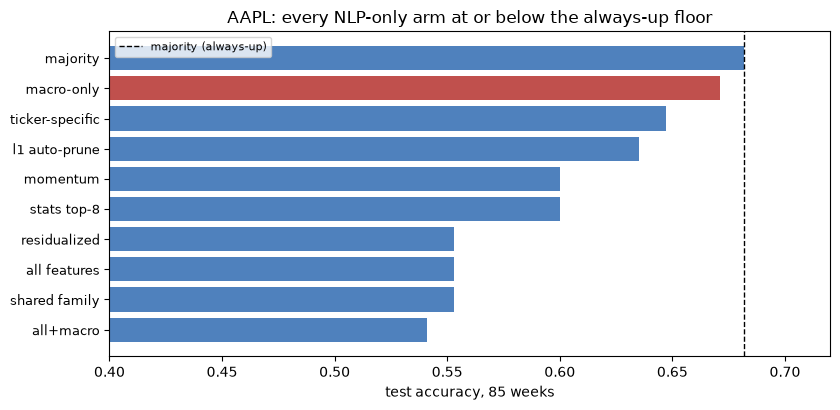

In [13]:
banner("L7 ARMS · spine step 7/7 - can any model built on these signals beat always-up? each arm answers one named question; pre-registered before the agent loop")
ARM_QUESTIONS = {
    "majority": "always predict the training majority class",
    "momentum": "this week's direction repeats next week",
    "ticker-specific": "the company bin plus this ticker's mined words only",
    "shared family": "generic industry themes only, no company words",
    "all features": "every NLP signal",
    "all+macro": "every NLP signal plus market state",
    "macro-only": "market state alone: do the news signals add anything beyond it?",
    "residualized": "NLP signals with the market component stripped out: is anything left?",
    "stats top-8": "the 8 strongest training correlations only",
    "l1 auto-prune": "everything, sparsity-selected",
}
for k, q in ARM_QUESTIONS.items():
    print(f"   {k:<16} {q}")
MACRO = ["SPY_ret", "SPY_vol", "dgs10_chg"]
CS = [0.03, 0.1, 0.3, 1.0]


def residualize(df, cols, tr_mask):
    Z = np.column_stack([np.ones(tr_mask.sum()), df.loc[tr_mask, MACRO].fillna(0).to_numpy()])
    beta, *_ = np.linalg.lstsq(Z, df.loc[tr_mask, cols].fillna(0).to_numpy(), rcond=None)
    Zh = np.column_stack([np.ones(len(df)), df[MACRO].fillna(0).to_numpy()])
    resid = df[cols].fillna(0).to_numpy() - Zh @ beta
    return pd.DataFrame(resid, index=df.index, columns=cols)


def run_arms(t):
    df = ticker_frame(t)
    tr = df[TR & df["fwd"].notna()]
    va = df[VA & df["fwd"].notna()]
    te = df[TE & df["fwd"].notna()]
    if len(tr) < 150 or len(te) < 30:
        return None
    ytr, yva, yte = tr["y"].astype(int), va["y"].astype(int), te["y"].astype(int)
    trva = pd.concat([tr, va])
    out = {"n": (len(tr), len(va), len(te)), "te": te, "tr": tr, "va": va, "arms": {}}

    maj = float(ytr.mean() >= 0.5)
    pred = np.full(len(te), maj)
    out["arms"]["majority"] = {"pred": pred, "correct": pred == yte.values, "prob": None, "fitted": None}
    mom = (te["ret"] > 0).astype(float).values
    out["arms"]["momentum"] = {"pred": mom, "correct": mom == yte.values, "prob": None, "fitted": None}

    def make(pen, C):
        return LogisticRegression(max_iter=3000, C=C, penalty=pen,
                                  solver="liblinear" if pen == "l1" else "lbfgs",
                                  random_state=RANDOM_STATE)

    def fit(cols, pen, frames=None):
        dtr, dva, dte, dtrva = frames if frames else (tr, va, te, trva)
        best = None
        for C in CS:
            pipe = Pipeline([("scale", StandardScaler()), ("clf", make(pen, C))])
            pipe.fit(dtr[cols].fillna(0), ytr)
            try:
                auc = roc_auc_score(yva, pipe.predict_proba(dva[cols].fillna(0))[:, 1])
            except ValueError:
                auc = np.nan
            if best is None or (not np.isnan(auc) and (np.isnan(best[0]) or auc > best[0])):
                best = (auc, C)
        pipe = Pipeline([("scale", StandardScaler()), ("clf", make(pen, best[1]))])
        pipe.fit(dtrva[cols].fillna(0), dtrva["y"].astype(int))
        prob = pipe.predict_proba(dte[cols].fillna(0))[:, 1]
        pred = (prob > 0.5).astype(float)
        return {"pred": pred, "correct": pred == yte.values, "prob": prob,
                "fitted": (pipe, cols, best[1], pen)}

    specific = [c for c in rosters[t].columns if "|" in c]
    shared = [c for c in rosters[t].columns if c.endswith(" [c]") or c.endswith(" [e]")]
    rmap = {}
    for c in rosters[t].columns:
        s = tr[c]
        if s.std() > 0:
            rmap[c] = abs(float(np.corrcoef(s, tr["fwd"])[0, 1]))
    top8 = sorted(rmap, key=rmap.get, reverse=True)[:8]
    resid_all = residualize(df, specific + shared, TR & df["fwd"].notna())
    df_r = df.copy()
    df_r[resid_all.columns] = resid_all
    tr_r = df_r[TR & df["fwd"].notna()]
    va_r = df_r[VA & df["fwd"].notna()]
    te_r = df_r[TE & df["fwd"].notna()]
    trva_r = pd.concat([tr_r, va_r])
    use = [("ticker-specific", specific, None), ("shared family", shared, None),
           ("all features", specific + shared, None), ("all+macro", specific + shared + MACRO, None),
           ("macro-only", MACRO, None), ("stats top-8", top8, None),
           ("residualized", specific + shared, (tr_r, va_r, te_r, trva_r))]
    for name, cols, frames in use:
        out["arms"][name] = fit(cols, "l2", frames)
    out["arms"]["l1 auto-prune"] = fit(specific + shared + MACRO, "l1")
    return out


res = run_arms(TICKER)
assert res is not None
yte = res["te"]["y"].astype(int)
maj_ok = res["arms"]["majority"]["correct"]
rows = []
for name, a in res["arms"].items():
    row = {"arm": name, "test accuracy": round(float(a["correct"].mean()), 3),
           "test F1(up)": round(f1_score(yte, a["pred"].astype(int), zero_division=0), 3),
           "long weeks": int(a["pred"].sum()),
           "McNemar p vs majority": round(mcnemar_p(a["correct"], maj_ok), 3)}
    if a["prob"] is not None:
        row["test AUC"] = round(roc_auc_score(yte, a["prob"]), 3)
    rows.append(row)
eval_table = pd.DataFrame(rows).set_index("arm")
print(f"weeks: train/valid/test = {res['n'][0]}/{res['n'][1]}/{res['n'][2]}")
display(eval_table)
print("TEST ACCURACIES " + json.dumps({r["arm"]: r["test accuracy"] for r in rows}))
print(f"verdict: no arm beats always-up ({eval_table.loc['majority', 'test accuracy']:.3f}); macro-only reaches {eval_table.loc['macro-only', 'test accuracy']:.3f} - market state alone explains nearly everything, and this is the floor the agent layer must justify itself against")

fig, ax = plt.subplots(figsize=(8.5, 4.2))
order = eval_table.sort_values("test accuracy")
ax.barh(range(len(order)), order["test accuracy"],
        color=["#c0504d" if i == "macro-only" else "#4f81bd" for i in order.index])
ax.set_yticks(range(len(order)), order.index, fontsize=9)
ax.axvline(eval_table.loc["majority", "test accuracy"], color="black", ls="--", lw=1, label="majority (always-up)")
ax.set_xlim(0.40, 0.72)
ax.legend(fontsize=8)
ax.set_xlabel(f"test accuracy, {res['n'][2]} weeks")
ax.set_title(f"{TICKER}: every NLP-only arm at or below the always-up floor")
plt.tight_layout()
plt.show()

In [14]:
banner("L7.2 PANEL  the same pre-registered arms on every panel ticker")
panel_rows = []
for t in PANEL:
    r_ = run_arms(t)
    if r_ is None:
        print(f"{t}: skipped, insufficient weekly history")
        continue
    row = {"ticker": t, "weeks": r_["n"][2], "seeds": len(mined[t]),
           "majority": round(float(r_["arms"]["majority"]["correct"].mean()), 3)}
    for arm in ["momentum", "ticker-specific", "shared family", "all features", "all+macro",
                "macro-only", "residualized", "stats top-8", "l1 auto-prune"]:
        row[arm] = round(float(r_["arms"][arm]["correct"].mean()), 3)
    panel_rows.append(row)
panel_tbl = pd.DataFrame(panel_rows).set_index("ticker")
display(panel_tbl)
print(panel_tbl.to_string())
arm_cols = ["momentum", "ticker-specific", "shared family", "all features", "all+macro",
            "macro-only", "residualized", "stats top-8", "l1 auto-prune"]
wins = (panel_tbl[arm_cols].max(axis=1) <= panel_tbl["majority"] + 1e-9)
print(f"verdict: majority wins or ties {int(wins.sum())} of {len(panel_tbl)} tickers across the panel - weekly direction from this corpus sits at the baseline for every NLP arm, matching the probes")


L7.2 PANEL  the same pre-registered arms on every panel ticker


,weeks,seeds,majority,momentum,ticker-specific,shared family,all features,all+macro,macro-only,residualized,stats top-8,l1 auto-prune
ticker,,,,,,,,,,,,
AAPL,85,5,0.682,0.600,0.647,0.553,0.553,0.541,0.671,0.553,0.600,0.635
XOM,85,3,0.576,0.518,0.447,0.482,0.482,0.529,0.447,0.494,0.506,0.565
JPM,85,4,0.541,0.576,0.482,0.518,0.494,0.529,0.541,0.506,0.541,0.459
PFE,85,1,0.553,0.482,0.588,0.518,0.494,0.494,0.588,0.482,0.494,0.553
F,85,0,0.506,0.553,0.541,0.447,0.471,0.471,0.482,0.447,0.529,0.494
CAT,85,0,0.553,0.529,0.553,0.565,0.565,0.576,0.482,0.529,0.565,0.447


        weeks  seeds  majority  momentum  ticker-specific  shared family  all features  all+macro  macro-only  residualized  stats top-8  l1 auto-prune
ticker                                                                                                                                                 
AAPL       85      5     0.682     0.600            0.647          0.553         0.553      0.541       0.671         0.553        0.600          0.635
XOM        85      3     0.576     0.518            0.447          0.482         0.482      0.529       0.447         0.494        0.506          0.565
JPM        85      4     0.541     0.576            0.482          0.518         0.494      0.529       0.541         0.506        0.541          0.459
PFE        85      1     0.553     0.482            0.588          0.518         0.494      0.494       0.588         0.482        0.494          0.553
F          85      0     0.506     0.553            0.541          0.447         0.471  

## 8. The spine, retold

In [15]:
banner("THE SPINE, RETOLD - every number below was computed and printed by the cells above")
best = scr.iloc[0]
print(f"INPUT: one ticker string, {TICKER}.")
print(f"1. The decade's {len(heads):,} headlines reduce to {len(clean):,} once wire boilerplate ({heads['is_template'].mean():.0%}) and same-week duplicates are deleted.")
print(f"2. One vocabulary pass keeps thing-words over market-process words and groups them into {shared_features.shape[1]} generic industry themes - a baseline that is not about any company.")
print(f"3. {TICKER} resolves to the words {resolve[TICKER]}; {int(m_mask[TICKER].sum())} headlines name it, in {int((company_series[TICKER]['COMPANY|share'] > 0).sum())} of {len(wk_index)} weeks.")
print(f"4. {len(mined[TICKER])} words ride along with those mentions at >=2x the baseline rate: {[r['seed'] for r in mined[TICKER]]} - transmission candidates, still unjudged.")
print(f"5. Each becomes a weekly coverage and tone signal over all headlines; with the company bin and the industry family: {rosters[TICKER].shape[1]} features x {len(rosters[TICKER])} weeks.")
print(f"6. On {int(TR.sum())} training weeks the strongest single signal is {best['feature']} (r={best['r']:+.3f}) and nothing survives multiple testing (min q={scr['q'].min():.2f}).")
print(f"7. On {res['n'][2]} test weeks every arm sits at or below always-up ({eval_table.loc['majority', 'test accuracy']:.3f}); macro-only reaches {eval_table.loc['macro-only', 'test accuracy']:.3f} - market state alone explains nearly everything.")
print("NEXT: the agent layer proposes, routes, judges, decides, and audits - reading exactly the tables printed above, measured against this floor.")


THE SPINE, RETOLD - every number below was computed and printed by the cells above
INPUT: one ticker string, AAPL.
1. The decade's 436,564 headlines reduce to 289,147 once wire boilerplate (30%) and same-week duplicates are deleted.
2. One vocabulary pass keeps thing-words over market-process words and groups them into 61 generic industry themes - a baseline that is not about any company.
3. AAPL resolves to the words ['apple', 'aapl']; 825 headlines name it, in 276 of 560 weeks.
4. 5 words ride along with those mentions at >=2x the baseline rate: ['tablet', 'holiday', 'energy', 'dip', 'watch'] - transmission candidates, still unjudged.
5. Each becomes a weekly coverage and tone signal over all headlines; with the company bin and the industry family: 72 features x 560 weeks.
6. On 390 training weeks the strongest single signal is campaign [c] (r=-0.122) and nothing survives multiple testing (min q=0.46).
7. On 85 test weeks every arm sits at or below always-up (0.682); macro-only reac

## 9. The agent layer - six roles, five LLM calls plus the deterministic market lane

In [16]:
banner("L8.0 LLM LAYER - one call pattern for every agent: temperature 0, disk cache keyed by prompt hash, standing block printed once, session tables printed in the cell, verbatim reply printed")
import hashlib
import os
import time
import requests
from dotenv import load_dotenv

load_dotenv(REPO_ROOT / ".env")
GEMINI_API_KEY = os.environ.get("GEMINI_API_KEY")
LLM_MODEL = "gemini-3.5-flash-lite"
PRINTED_BLOCKS = set()
CALL_LOG = []

if GEMINI_API_KEY:
    from google import genai
    from google.genai import types
    gemini_client = genai.Client(api_key=GEMINI_API_KEY)


def parse_json_reply(text):
    text = str(text).strip().removeprefix("```json").removeprefix("```").removesuffix("```")
    start, end = text.find("{"), text.rfind("}")
    try:
        return json.loads(text[start:end + 1])
    except (json.JSONDecodeError, AttributeError):
        return {}


def call_llm(agent, standing_block, tables_block):
    prompt = standing_block + "\n\n" + tables_block
    if agent not in PRINTED_BLOCKS:
        print(f"--- STANDING BLOCK: {agent} (printed once; every {agent} prompt = this block + that session's tables) ---")
        print(standing_block)
        PRINTED_BLOCKS.add(agent)
    key = hashlib.sha256((LLM_MODEL + prompt).encode()).hexdigest()[:24]
    cache_file = LLM_CACHE / f"{key}.json"
    if cache_file.exists():
        reply = json.loads(cache_file.read_text(encoding="utf-8"))
        CALL_LOG.append((agent, "cache"))
    elif GEMINI_API_KEY:
        for attempt in range(3):
            try:
                reply = gemini_client.models.generate_content(model=LLM_MODEL, contents=prompt,
                                                              config=types.GenerateContentConfig(temperature=0.0)).text
                break
            except Exception as exc:
                if attempt == 2:
                    print(f"[{agent}] API call failed after retries: {type(exc).__name__}: {str(exc)[:120]}")
                    return None
                time.sleep(2 * (attempt + 1))
        cache_file.write_text(json.dumps(reply), encoding="utf-8")
        CALL_LOG.append((agent, "live"))
    else:
        print(f"[{agent}] SKIPPED - GEMINI_API_KEY not set; the NLP-only arms above stand alone")
        return None
    print(f"--- {agent} REPLY (verbatim) ---")
    print(reply)
    return parse_json_reply(reply)

print("LLM layer armed." if GEMINI_API_KEY else "GEMINI_API_KEY not set; agent cells below are skipped with a notice.")


L8.0 LLM LAYER - one call pattern for every agent: temperature 0, disk cache keyed by prompt hash, standing block printed once, session tables printed in the cell, verbatim reply printed


LLM layer armed.


In [17]:
banner("L9 MEMORY - the persistent banned-vocabulary ledger: pre-seeded from the deterministic wire/suffix/calendar lists (the former hardcodes), extended only by planner strikes that generalize across tickers")
MEMORY_FILE = DATA_PROCESSED / "agent_memory.json"
memory = {
    "banned": [{"word": w, "origin": "deterministic", "reason": "wire format / corporate suffix / calendar language"}
               for w in sorted(set(NAME_STOP) | set(STOP_EXTRA))],
    "ledger": [],
    "planner_notes": [],
}
if MEMORY_FILE.exists():
    archived = DATA_PROCESSED / "agent_memory_archived.json"
    archived.write_text(MEMORY_FILE.read_text(encoding="utf-8"), encoding="utf-8")
    print(f"prior memory archived at {archived.name}; every loop run starts from the deterministic seed, so reruns are deterministic")
MEMORY_FILE.write_text(json.dumps(memory, indent=1), encoding="utf-8")


def banned_words():
    return {b["word"] for b in memory["banned"]}


def write_ban(word, reason, origin="planner"):
    if word not in banned_words():
        memory["banned"].append({"word": word, "origin": origin, "reason": reason})
        MEMORY_FILE.write_text(json.dumps(memory, indent=1), encoding="utf-8")
        print(f"MEMORY WRITE: '{word}' banned for all later tickers - {reason}")


print(f"{len(banned_words())} pre-seeded bans (origin: deterministic); planner strikes with generalize=true append here and print when they bite")


L9 MEMORY - the persistent banned-vocabulary ledger: pre-seeded from the deterministic wire/suffix/calendar lists (the former hardcodes), extended only by planner strikes that generalize across tickers
prior memory archived at agent_memory_archived.json; every loop run starts from the deterministic seed, so reruns are deterministic
391 pre-seeded bans (origin: deterministic); planner strikes with generalize=true append here and print when they bite


In [18]:
banner("L8.1 TOOLS - the registry agent actions dispatch into; dynamic use means the agent's reply decides which tool runs, with which pre-registered parameters")
EDGAR_CACHE = DATA_PROCESSED / "edgar_cache"


def tool_headline_sample(term, k=5):
    idx = [i for i, s in enumerate(concept_sets) if term in s]
    if not idx:
        return []
    seed = RANDOM_STATE + int(hashlib.md5(term.encode()).hexdigest()[:8], 16)
    rng = np.random.default_rng(seed)
    picks = rng.choice(len(idx), size=min(k, len(idx)), replace=False)
    return [{"week_offset": -int((wk_index[-1] - week_of[idx[j]]).n // 7),
             "headline": clean["headline"].iloc[idx[j]], "label": labels_all[idx[j]]} for j in picks]


def tool_stats(t, features):
    return stats_table(t).set_index("feature").loc[features].reset_index()


def tool_company_profile(t):
    info = yf.Ticker(t).info or {}
    return " ".join(str(x) for x in [info.get("longName"), info.get("sector"), info.get("industry"), info.get("longBusinessSummary")] if x)


def tool_edgar_filings(t, now):
    EDGAR_CACHE.mkdir(exist_ok=True)
    cf = EDGAR_CACHE / f"{t}.json"
    if cf.exists():
        data = json.loads(cf.read_text(encoding="utf-8"))
    else:
        try:
            headers = {"User-Agent": "aai-520-university-research/1.0 (course project; no contact inbox)", "Accept": "application/json"}
            r1 = requests.get("https://www.sec.gov/files/company_tickers.json", headers=headers, timeout=30)
            r1.raise_for_status()
            mapping = r1.json()
            cik = int(next(v["cik_str"] for v in mapping.values() if v["ticker"] == t))
            time.sleep(0.4)
            r2 = requests.get(f"https://data.sec.gov/submissions/CIK{cik:010d}.json", headers=headers, timeout=30)
            r2.raise_for_status()
            sub = r2.json()
            data = {"cik": cik, "filings": [{"form": f, "date": d} for f, d in zip(sub["filings"]["recent"]["form"], sub["filings"]["recent"]["filingDate"])][:80]}
            cf.write_text(json.dumps(data), encoding="utf-8")
        except Exception as exc:
            print(f"EDGAR fetch failed for {t} ({type(exc).__name__}: {str(exc)[:100]}); the earnings desk proceeds without filings")
            return []
    out = []
    for f in data["filings"]:
        wk = int((now - pd.Timestamp(f["date"])).days // 7)
        if 0 <= wk <= 260:
            out.append(f"{f['form']} ({wk} weeks before now)")
    return out[:12]

print("registry: headline_sample(term) | stats(ticker, features) | company_profile(ticker) | edgar_filings(ticker, now) | remine(ticker, level='escalated', bans)")


L8.1 TOOLS - the registry agent actions dispatch into; dynamic use means the agent's reply decides which tool runs, with which pre-registered parameters
registry: headline_sample(term) | stats(ticker, features) | company_profile(ticker) | edgar_filings(ticker, now) | remine(ticker, level='escalated', bans)


In [19]:
banner(f"L8.2 PROPOSER - before the corpus gets a say: which words' coverage plausibly transmits to {TICKER}? profile text only; no numbers, no dates; every proposal then passes the same deterministic gates as mined seeds")
PROPOSER_BLOCK = """You are the concept proposer in an investment-research pipeline. You receive one company's self-description and nothing else - no market data, no news, no numbers. Name at most 10 terms whose news coverage would plausibly transmit to this company's business through a channel it actually earns or spends through. Strongly prefer single plain words a financial newswire headline would use (chip, battery, retail, refinery); use a two-word term only for fixed phrases (supply chain, crude oil). For each term give a one-line hunch on the expected transmission. Prefer specific things (products, inputs, demand drivers, regulations it faces); never market-process words (profit, outlook, ratings, sector, prices) - those are never admitted downstream. Reply with JSON only: {"terms": [{"term": "...", "hunch": "..."}]}"""


def propose_terms(t):
    tables = "COMPANY PROFILE:\n" + tool_company_profile(t)[:1800]
    reply = call_llm("proposer", PROPOSER_BLOCK, tables)
    return [{"seed": str(i.get("term", "")).lower().strip(), "hunch": str(i.get("hunch", ""))[:120]}
            for i in reply.get("terms", []) if str(i.get("term", "")).strip()][:10]


def admit_proposals(t, props):
    rows = []
    for p in props:
        term = p["seed"]
        if term in banned_words() or (set(term.split()) & banned_words()):
            rows.append({**p, "fate": "banned in memory"})
            continue
        total = corpus_member.get(term, 0)
        weeks_sup = len(set(cw.get(term, [])))
        marg = vec_margin(term)
        if total < 25 or weeks_sup < 15:
            rows.append({**p, "fate": f"died on support ({total} headlines, {weeks_sup} weeks)"})
        elif not (term in LEXICON or (marg is not None and marg > 0.25)):
            rows.append({**p, "fate": "died on vocabulary test (margin " + ("none" if marg is None else f"{marg:.2f}") + ")"})
        else:
            rows.append({**p, "fate": "admitted"})
    return rows


def build_roster(t, props=None):
    rows = [{"seed": r["seed"], "provenance": "mined", "gloss": "co-occurs with this company's mention headlines"} for r in mined[t]]
    if props:
        display(pd.DataFrame(admit_proposals(t, props)))
        for r in admit_proposals(t, props):
            if r["fate"] == "admitted":
                existing = next((m for m in rows if m["seed"] == r["seed"]), None)
                if existing:
                    existing["provenance"] = "both"
                else:
                    rows.append({"seed": r["seed"], "provenance": "proposed", "gloss": r["hunch"]})
    return rows


print("proposer exercised at each ticker's first session in the loop below; standing block, tables, and verbatim reply print there")


L8.2 PROPOSER - before the corpus gets a say: which words' coverage plausibly transmits to AAPL? profile text only; no numbers, no dates; every proposal then passes the same deterministic gates as mined seeds
proposer exercised at each ticker's first session in the loop below; standing block, tables, and verbatim reply print there


In [20]:
banner(f"L8.3 PLANNER - routing {TICKER}: one action per candidate; semantic drop reasons only; generalize=true writes a persistent ban; escalate sends the analyzer for another run at the pre-registered lower floor")
PLANNER_BLOCK = """You plan research for one company. The roster lists candidate signal words, each with provenance (mined from headlines naming the company, proposed from the company profile, or both) and a gloss. You see no numbers. For each candidate, exactly one action:
drop - a phrase fragment, generic market-process language, or calendar language; one semantic reason. Set generalize true ONLY for market-process, calendar, or wire-format language - words that could not be a real transmission channel for ANY company (profit, outlook, plc, corp). Commodity, sector, and industry words are NOT generalizable - they transmit for some companies even when not this one; when in doubt set false.
read - the news desk must inspect what the word actually captures; say what you suspect. At most 5 across the roster.
full - route to the statistics lane and the earnings desk.
Also return escalate: true at most once - it re-runs the miner at a lower admission floor with every dropped and banned word excluded, surfacing replacement candidates; use it only if drops leave the roster thin.
Reply with JSON only: {"actions": [{"term": "...", "action": "drop|read|full", "reason": "...", "generalize": false}], "escalate": false, "plan_summary": "..."}"""


def plan_research(t, roster_rows, notes=""):
    lines = [f"COMPANY: {t}", f"CANDIDATE ROSTER ({len(roster_rows)}):"]
    lines += [f"- {r['seed']} [{r['provenance']}]: {r['gloss']}" for r in roster_rows]
    agent_bans = [b["word"] for b in memory["banned"] if b["origin"] != "deterministic"][-12:]
    if agent_bans:
        lines.append("WORDS ALREADY BANNED BY EARLIER SESSIONS OF THIS SYSTEM (persistent memory; never re-admit them): " + ", ".join(agent_bans))
    if notes:
        lines.append("PLANNER NOTES FROM EARLIER SESSIONS:")
        lines.append(notes)
    return call_llm("planner", PLANNER_BLOCK, "\n".join(lines))


def dispatch_plan(plan, roster_rows):
    acts = {str(a.get("term", "")).lower().strip(): a for a in plan.get("actions", [])}
    for r in roster_rows:
        a = acts.get(r["seed"], {"action": "full", "reason": "no planner verdict; defaults to full"})
        r["action"] = str(a.get("action", "full"))
        r["reason"] = str(a.get("reason", ""))
        if r["action"] == "drop" and a.get("generalize"):
            write_ban(r["seed"], r["reason"])
    print(f"PLANNER plan_summary: {plan.get('plan_summary', '')}")
    print("dispatch: " + ", ".join(f"{r['seed']}->{r['action']}" for r in roster_rows))
    return roster_rows


def remine_escalated(t, exclude):
    rows = sorted(mine_seeds(t, min_hits=3, min_lift=1.5, exclude=exclude), key=lambda r: -r["mention_hits"])[:6]
    return [{"seed": r["seed"], "provenance": "mined-escalated", "gloss": "surfaced at the escalated floor after planner strikes"}
            for r in rows]


print("planner exercised at each ticker's first session in the loop below; escalate and memory writes print there")


L8.3 PLANNER - routing AAPL: one action per candidate; semantic drop reasons only; generalize=true writes a persistent ban; escalate sends the analyzer for another run at the pre-registered lower floor
planner exercised at each ticker's first session in the loop below; escalate and memory writes print there


In [21]:
banner(f"L8.4 NEWS DESK - term quality for {TICKER}: five sampled headlines per read-assigned word, spread across the decade; verdicts clean / diluted / contaminated with quoted evidence")
NEWS_BLOCK = """You inspect candidate signal words for one company. For each word you get five headlines containing it, sampled across the decade (week offset relative to the corpus end; negative = earlier), each with a tone label from a financial sentiment classifier. For each word:
captures: one line on what the word actually measures across these headlines.
verdict - exactly one of:
clean: one sense, the intended thing.
diluted: the wanted sense dominates but other senses mix in - still usable, noisier.
contaminated: the unwanted sense is most of what weekly counts would track, or two senses fight and cannot be separated; quote the proving headline in evidence.
Reply with JSON only: {"verdicts": [{"term": "...", "captures": "...", "verdict": "clean|diluted|contaminated", "evidence": "..."}]}"""


def news_desk(t, terms):
    lines = [f"COMPANY: {t}"]
    for term in terms:
        lines.append(f"TERM: {term}")
        for s in tool_headline_sample(term, 5):
            lines.append(f"  week {s['week_offset']:>5} | {s['label']:>8} | {s['headline']}")
    return call_llm("news", NEWS_BLOCK, "\n".join(lines))


print("news desk exercised on planner-assigned read terms inside the loop below, with the boundary audit on one cleared term")


L8.4 NEWS DESK - term quality for AAPL: five sampled headlines per read-assigned word, spread across the decade; verdicts clean / diluted / contaminated with quoted evidence
news desk exercised on planner-assigned read terms inside the loop below, with the boundary audit on one cleared term


In [22]:
banner("L8.5 EARNINGS DESK + MARKET LANE - transmission channels judged on the profile, recent filings, and the news desk's captures; the statistics lane is deterministic math with pre-registered weights (no LLM)")
EARNINGS_BLOCK = """You judge transmission channels for one company. You receive the company profile, a list of recent SEC filings (form and weeks-before-now), and each candidate signal word with the news desk's description of what its coverage actually captures. For each candidate:
channel: revenue | cost | demand | financing | none - through which line of this company's business the captured coverage transmits.
direction: helps | hurts | unclear.
mechanism: one line. For channel none, the mechanism line must say why it does not transmit to this company.
Judge the described coverage, not the bare word. Reply with JSON only: {"channels": [{"term": "...", "channel": "...", "direction": "...", "mechanism": "..."}]}"""


def earnings_desk(t, terms, captures, now):
    lines = [f"COMPANY: {t}", "PROFILE:", tool_company_profile(t)[:900], "RECENT SEC FILINGS:"]
    filings = tool_edgar_filings(t, now)
    lines += [("  " + f) for f in filings] or ["  none within the window"]
    lines.append("CANDIDATES (with what each one's coverage captures, per the news desk):")
    lines += [f"- {term}: {captures.get(term, '')}" for term in terms]
    reply = call_llm("earnings", EARNINGS_BLOCK, "\n".join(lines))
    out = {}
    for c in (reply or {}).get("channels", []):
        out[str(c.get("term", "")).lower().strip()] = c
    return out


MARKET_W = {"abs_r": 0.45, "stable": 0.20, "r_exc": 0.25, "support": 0.10}
print("market lane weights, pre-registered before the loop: " + json.dumps(MARKET_W))


def market_lane(t, terms, through):
    scr = stats_table(t, through=through)
    if scr.empty:
        return {term: {} for term in terms}
    scr = scr.set_index("feature")
    out = {}
    for term in terms:
        best = None
        for suf in ("share", "senti"):
            col = f"{term}|{suf}"
            if col in scr.index and (best is None or abs(scr.loc[col, "r"]) > abs(scr.loc[best, "r"])):
                best = col
        if best is None:
            out[term] = {}
            continue
        row = scr.loc[best]
        score = (MARKET_W["abs_r"] * min(abs(row["r"]), 0.3) / 0.3
                 + MARKET_W["stable"] * int(bool(row["stable"]))
                 + MARKET_W["r_exc"] * min(abs(row["r_exc"]), 0.3) / 0.3
                 + MARKET_W["support"] * min(row["support"], 300) / 300)
        out[term] = {"col": best, "r": row["r"], "r_spy": row["r_spy"], "r_exc": row["r_exc"],
                     "stable": bool(row["stable"]), "market_score": round(float(score), 3),
                     "tracking": bool(abs(row["r_spy"]) >= 0.8 * abs(row["r"]) and abs(row["r_exc"]) < 0.05)}
    return out


L8.5 EARNINGS DESK + MARKET LANE - transmission channels judged on the profile, recent filings, and the news desk's captures; the statistics lane is deterministic math with pre-registered weights (no LLM)
market lane weights, pre-registered before the loop: {"abs_r": 0.45, "stable": 0.2, "r_exc": 0.25, "support": 0.1}


## 10. The walk-forward loop - 36 sessions, decisions under as-of information

In [23]:
banner("L10 WALK-FORWARD LOOP - every session's tables are computed as-of its week; agents never see outcomes or calendar dates; first sessions are staggered so later tickers inherit earlier bans and planner notes")
SYNTHESIS_BLOCK = """You are the decision layer of an investment-research pipeline for one company. Your job: call the direction of this company's coming week - buy = you expect the coming week's close higher, sell = lower. hold is abstention and is available only when the printed evidence genuinely balances; a pipeline that always abstains provides nothing, but never manufacture conviction the tables do not show. strength grades your conviction: 1 = marginal, 2 = supported by the tables, 3 = coherent across several features.
You receive the frozen verdict table (each surviving signal word with what its coverage captures, its transmission channel, and its statistics-lane score), this week's values with trailing averages, the company's own coverage bin, the market state, and this system's ledger of its own prior calls and their realized outcomes.
Keep every listed feature unless you give a per-feature removal reason. Then: direction = buy | sell | hold; strength = 1 | 2 | 3; evidence = the printed values your call rests on; strength_boundary = what evidence would move you one grade down; rationale = at most two sentences. Where a feature's statistics conflict with what it captures, say so. The ledger is short - it may temper strength, never override evidence. Use nothing outside these tables; do no arithmetic.
Reply with JSON only: {"final_features": ["..."], "removals": [{"term": "...", "reason": "..."}], "direction": "...", "strength": 1, "evidence": ["..."], "strength_boundary": "...", "rationale": "..."}"""

EVALUATOR_BLOCK = """You audit a decision against exactly the tables its author saw. Check both directions:
1. every feature the decision lists exists in the verdict table; 2. every verdict-table survivor is retained or has a stated removal reason; 3. every cited value matches the printed tables; 4. no claim untraceable to the tables (outside knowledge); 5. no arithmetic performed by the decision (numbers may be quoted, never computed).
Reply with JSON only: {"checks": {"listed_valid": true, "survivors_accounted": true, "citations_match": true, "no_outside_knowledge": true, "no_arithmetic": true}, "violations": ["..."], "verdict": "accept|revise"}"""


def week_off(w):
    return -int((wk_index[-1] - w).n // 7)


def syn_tables(t, w, vt):
    X = rosters[t]
    lines = [f"COMPANY: {t} (week {week_off(w)} relative to corpus end)",
             "VERDICT TABLE (frozen at this company's first session):"]
    lines += vt["rows"] or ["  (no surviving concept features; the company bin and market state carry this decision)"]
    lines.append("THIS WEEK'S VALUES (pipeline-computed against each feature's own history up to this week - these features are sparse: most weeks are zero):")
    watch_share = [f"{term}|share" for term in vt["survivors"]] + ["COMPANY|share"]
    watch_senti = [f"{term}|senti" for term in vt["survivors"]] + ["COMPANY|senti"]
    for col in watch_share:
        if col in X.columns:
            hist = X[col].loc[:w].dropna()
            if len(hist) >= 5:
                now_v = float(hist.iloc[-1])
                pct = float((hist <= now_v).mean())
                nz = float((hist > 0).mean())
                if now_v > 0 and pct >= 0.9:
                    level = "elevated"
                elif now_v > 0 and nz < 0.5:
                    level = "active (typically quiet)"
                elif now_v == 0:
                    level = "quiet (zero coverage this week)"
                else:
                    level = "typical"
                lines.append(f"  {col}: now {now_v:+.4f} | percentile of own history {pct:.0%} | nonzero in {nz:.0%} of weeks | level: {level}")
    for col in watch_senti:
        if col in X.columns:
            now_v = float(X[col].loc[w])
            tone = "positive" if now_v > 0.05 else ("negative" if now_v < -0.05 else "mixed")
            lines.append(f"  {col}: now {now_v:+.4f} | tone: {tone}")
    lines.append("MARKET STATE THIS WEEK:")
    for c in ["SPY_ret", "SPY_vol", "dgs10_chg"]:
        v = float(wkpx[c].reindex(X.index).loc[w])
        gloss = (" (an up week for the market)" if c == "SPY_ret" and v > 0
                 else " (a down week for the market)" if c == "SPY_ret" and v < 0
                 else " (elevated volatility)" if c == "SPY_vol" and v > 0.03
                 else " (calm volatility)" if c == "SPY_vol" else "")
        lines.append(f"  {c}: {v:+.4f}{gloss}")
    dfr = ticker_frame(t)
    m_asof = (dfr.index <= w) & dfr["fwd"].notna() & dfr["SPY_ret"].notna()
    if int(m_asof.sum()) > 50:
        r_mkt = float(np.corrcoef(dfr.loc[m_asof, "SPY_ret"], dfr.loc[m_asof, "fwd"])[0, 1])
        mrel = ("down market weeks historically preceded weaker weeks for this ticker" if r_mkt > 0.03
                else "down market weeks historically preceded stronger weeks for this ticker" if r_mkt < -0.03
                else "market weeks had no clear relation to this ticker's next week")
        lines.append(f"  market-relation (window to date): {mrel} (r={r_mkt:+.3f})")
    rec = sorted([i for i in np.where(m_mask[t])[0] if 0 <= (w - week_of[i]).n <= 4], key=lambda i: week_of[i])[-5:]
    lines.append("RECENT HEADLINES NAMING THIS COMPANY (last month, with tone labels):")
    if rec:
        for i in rec:
            lines.append(f"  [{labels_all[i]:>8}] {clean['headline'].iloc[i][:90]}")
    else:
        lines.append("  (no company-naming headlines in the last month)")
    led = [r for r in memory["ledger"] if r["ticker"] == t]
    lines.append("MEMORY LEDGER (this system's prior calls for this company, realized outcomes only):")
    if led:
        lines += [f"  session {r['session']}: {r['direction']} strength {r['strength']} -> realized {r['realized']:+.1%}" for r in led]
    else:
        lines.append("  (empty - first call for this company)")
    return "\n".join(lines)


def citation_twin(syn, tables_text):
    ev = syn.get("evidence", [])
    cited = re.findall(r"[-+]?\d+\.\d+", " ".join(ev) if isinstance(ev, list) else str(ev))
    norm = re.sub(r"[-+]?\d+\.\d+", lambda m: f"{float(m.group()):+.4f}", tables_text)
    return sorted({n for n in cited if f"{float(n):+.4f}" not in norm})


te_weeks = wk_index[TE]
grid = te_weeks[np.unique(np.round(np.linspace(0, len(te_weeks) - 1, 36)).astype(int))]
loop_sessions = sorted((grid[k + j * 6], t) for k, t in enumerate(PANEL) for j in range(6))
SMOKE = bool(os.environ.get("SMOKE"))
if SMOKE:
    loop_sessions = loop_sessions[:5]
    print(f"SMOKE RUN: first {len(loop_sessions)} sessions only")
print(f"{len(loop_sessions)} sessions, {len(PANEL)} tickers, first sessions staggered one grid slot apart")

frozen, session_log, flushed, session_failures = {}, [], {}, []
memory["ledger"] = []
memory["planner_notes"] = []
MEMORY_FILE.write_text(json.dumps(memory, indent=1), encoding="utf-8")

for si, (w, t) in enumerate(loop_sessions):
    print(f"\n--- SESSION {si + 1}/{len(loop_sessions)}: {t}, week {week_off(w)} ---")
    try:
        if t not in frozen:
            props = propose_terms(t) if GEMINI_API_KEY else []
            ros = build_roster(t, props)
            plan_ = plan_research(t, ros, notes="\n".join(memory["planner_notes"][-3:])) if GEMINI_API_KEY and ros else None
            nv = {}
            if plan_:
                ros = dispatch_plan(plan_, ros)
                if plan_.get("escalate"):
                    print("TOOL CALL: remine(level='escalated', bans=memory + planner strikes)")
                    repl = remine_escalated(t, {r["seed"] for r in ros} | banned_words())
                    print("replacements: " + (", ".join(r["seed"] for r in repl) or "none surfaced"))
                    if repl:
                        ros += dispatch_plan(plan_research(t, repl), repl)
            read_ = [r["seed"] for r in ros if r.get("action") == "read"]
            if GEMINI_API_KEY and read_:
                for v in news_desk(t, read_).get("verdicts", []):
                    nv[str(v.get("term", "")).lower().strip()] = v
                print(f"news desk twin: all {len(read_)} words already passed the deterministic wire and vocabulary gates - every contaminated verdict is work the filters cannot do")
                cleared = [x for x in read_ if nv.get(x, {}).get("verdict") == "clean"]
                if cleared:
                    t0 = cleared[0]
                    print(f"boundary audit on cleared term '{t0}' - five OTHER containing headlines, for the reader to hunt missed contamination:")
                    for s in tool_headline_sample(t0, 5):
                        print(f"   week {s['week_offset']:>5} | {s['label']:>8} | {s['headline']}")
            surv = [r["seed"] for r in ros
                    if r.get("action") != "drop" and nv.get(r["seed"], {}).get("verdict") != "contaminated"]
            gloss = {r["seed"]: r.get("gloss", "") for r in ros}
            caps = {term: nv.get(term, {}).get("captures") or gloss.get(term, "") for term in surv}
            now_ts = w.to_timestamp(how="end").normalize()
            ec = earnings_desk(t, surv, caps, now_ts) if GEMINI_API_KEY and surv else {}
            ml = market_lane(t, surv, w)
            rows_ = []
            for term in surv:
                m, ch = ml.get(term, {}), ec.get(term, {})
                r_v = float(m.get("r", 0) or 0)
                r_e = float(m.get("r_exc", 0) or 0)
                r_s = float(m.get("r_spy", 0) or 0)
                rel = ("higher coverage historically preceded weaker weeks" if r_v < -0.05
                       else "higher coverage historically preceded stronger weeks" if r_v > 0.05
                       else "no clear historical relation")
                spec = ("tracks this ticker more than the market" if abs(r_e) > 0.03 and abs(r_e) > abs(r_s)
                        else "mostly mirrors the market" if m.get("tracking") else "unclear specificity")
                rows_.append(f"- {term}: captures: {caps[term]} | channel: {ch.get('channel', '?')} {ch.get('direction', '?')} - {ch.get('mechanism', '')} | {rel} (r={m.get('r', '?')}); specificity: {spec}")
            scr_now = stats_table(t, through=w)
            if not scr_now.empty:
                scr_now = scr_now.set_index("feature")
                for c, gloss_ in [("COMPANY|share", "the volume of headlines naming the company"),
                                  ("COMPANY|senti", "the tone of headlines naming the company")]:
                    if c in scr_now.index:
                        rr = scr_now.loc[c]
                        r_v, r_e, r_s = float(rr["r"]), float(rr["r_exc"]), float(rr["r_spy"])
                        unit = "more coverage" if c.endswith("share") else "more positive tone"
                        relc = (f"{unit} historically preceded weaker weeks" if r_v < -0.05
                                else f"{unit} historically preceded stronger weeks" if r_v > 0.05
                                else "no clear historical relation")
                        spec = ("tracks this ticker more than the market" if abs(r_e) > 0.03 and abs(r_e) > abs(r_s)
                                else "mostly mirrors the market" if abs(rr["r_spy"]) >= 0.8 * abs(r_v) and abs(r_e) < 0.05
                                else "unclear specificity")
                        rows_.append(f"- COMPANY {'coverage' if c.endswith('share') else 'tone'}: captures: {gloss_} | {relc} (r={r_v:+.3f}); specificity: {spec}")
            frozen[t] = {"survivors": surv, "rows": rows_, "market": ml}
            memory["planner_notes"].append(f"{t}: {(plan_ or {}).get('plan_summary', 'no plan (no API key)')[:200]}")
            MEMORY_FILE.write_text(json.dumps(memory, indent=1), encoding="utf-8")
            print(f"FROZEN for {t}: {len(surv)} survivors - {', '.join(surv) or 'none; company bin + market state only'}")
        vt = frozen[t]
        for i, prev in enumerate([s for s in session_log if s["ticker"] == t]):
            if i >= flushed.get(t, 0):
                memory["ledger"].append({"ticker": t, "session": i + 1,
                                         "direction": prev["direction"], "strength": prev["strength"],
                                         "realized": prev["fwd"]})
        flushed[t] = len([s for s in session_log if s["ticker"] == t])
        MEMORY_FILE.write_text(json.dumps(memory, indent=1), encoding="utf-8")
        if not GEMINI_API_KEY:
            print("synthesis/evaluator SKIPPED (no API key)")
            continue
        tbl = syn_tables(t, w, vt)
        syn = call_llm("synthesis", SYNTHESIS_BLOCK, tbl)
        if not syn:
            continue
        ev = call_llm("evaluator", EVALUATOR_BLOCK, tbl + "\n\nDECISION UNDER AUDIT:\n" + json.dumps(syn))
        if ev.get("verdict") == "revise":
            print("EVALUATOR: revise - one resubmission follows")
            syn2 = call_llm("synthesis", SYNTHESIS_BLOCK,
                            tbl + "\n\nEVALUATOR FEEDBACK (one revision allowed, address the violations):\n" + json.dumps(ev))
            if syn2 and syn2.get("direction"):
                syn = syn2
        missing = citation_twin(syn, tbl)
        if missing:
            print(f"MECHANICAL TWIN: cited numbers absent from the tables: {missing}")
        direction = str(syn.get("direction", "hold")).lower()
        strength = syn.get("strength", 1)
        strength = int(strength) if str(strength).isdigit() and 1 <= int(strength) <= 3 else 1
        fwd_realized = float(ticker_frame(t)["fwd"].loc[w])
        session_log.append({"ticker": t, "week": w, "direction": direction, "strength": strength,
                            "fwd": fwd_realized, "syn": syn, "vt": vt})
        print(f"DECISION: {direction} strength {strength} | realized next week {fwd_realized:+.1%} | features {len(syn.get('final_features', []))}")
    except Exception as exc:
        session_failures.append((str(w), t, f"{type(exc).__name__}: {exc}"))
        print(f"SESSION FAILED ({type(exc).__name__}): {exc}")

for t in {s["ticker"] for s in session_log}:
    for i, prev in enumerate([s for s in session_log if s["ticker"] == t]):
        if i >= flushed.get(t, 0):
            memory["ledger"].append({"ticker": t, "session": i + 1, "direction": prev["direction"],
                                     "strength": prev["strength"], "realized": prev["fwd"]})
MEMORY_FILE.write_text(json.dumps(memory, indent=1), encoding="utf-8")
print(f"\nloop complete: {len(session_log)} decisions logged | memory: {len(memory['ledger'])} realized ledger rows, {len(memory['banned'])} bans ({sum(1 for b in memory['banned'] if b['origin'] != 'deterministic')} added by agents)")
if session_failures:
    print(f"{len(session_failures)} failed sessions:")
    for w_, t_, err in session_failures:
        print(f"  {t_} {w_}: {err}")


L10 WALK-FORWARD LOOP - every session's tables are computed as-of its week; agents never see outcomes or calendar dates; first sessions are staggered so later tickers inherit earlier bans and planner notes
SMOKE RUN: first 5 sessions only
5 sessions, 6 tickers, first sessions staggered one grid slot apart

--- SESSION 1/5: AAPL, week -12 ---


--- STANDING BLOCK: proposer (printed once; every proposer prompt = this block + that session's tables) ---
You are the concept proposer in an investment-research pipeline. You receive one company's self-description and nothing else - no market data, no news, no numbers. Name at most 10 terms whose news coverage would plausibly transmit to this company's business through a channel it actually earns or spends through. Strongly prefer single plain words a financial newswire headline would use (chip, battery, retail, refinery); use a two-word term only for fixed phrases (supply chain, crude oil). For each term give a one-line hunch on the expected transmission. Prefer specific things (products, inputs, demand drivers, regulations it faces); never market-process words (profit, outlook, ratings, sector, prices) - those are never admitted downstream. Reply with JSON only: {"terms": [{"term": "...", "hunch": "..."}]}
--- proposer REPLY (verbatim) ---
```json
{
  "terms": [
    {
      "term":

,seed,hunch,fate
0,chip,Changes in semiconductor availability and component costs directly impact hardware man...,died on vocabulary test (margin 0.24)
1,battery,Material costs and regulatory requirements regarding energy storage directly affect po...,"died on support (19 headlines, 15 weeks)"
2,tariff,Import duties and trade policy shifts alter the cost of goods manufactured overseas an...,died on vocabulary test (margin -0.22)
3,antitrust,Regulatory enforcement and legal challenges target App Store commission structures and...,"died on support (2 headlines, 2 weeks)"
4,advertising,Shifts in digital privacy rules and ad spend directly influence platform and licensing...,admitted
5,retail,Consumer spending trends and foot traffic fluctuations impact direct-to-consumer sales...,died on vocabulary test (margin -0.29)
6,supply chain,Logistics disruptions or manufacturing bottlenecks in assembly regions delay product a...,"died on support (18 headlines, 15 weeks)"
7,music,Licensing fees and digital content consumption trends dictate operational expenses and...,"died on support (19 headlines, 18 weeks)"
8,gaming,Content acquisition costs and user engagement levels drive performance in subscription...,admitted
9,credit,Default rates and lending partner terms affect the economics of co-branded financial s...,died on vocabulary test (margin -0.19)


--- STANDING BLOCK: planner (printed once; every planner prompt = this block + that session's tables) ---
You plan research for one company. The roster lists candidate signal words, each with provenance (mined from headlines naming the company, proposed from the company profile, or both) and a gloss. You see no numbers. For each candidate, exactly one action:
drop - a phrase fragment, generic market-process language, or calendar language; one semantic reason. Set generalize true ONLY for market-process, calendar, or wire-format language - words that could not be a real transmission channel for ANY company (profit, outlook, plc, corp). Commodity, sector, and industry words are NOT generalizable - they transmit for some companies even when not this one; when in doubt set false.
read - the news desk must inspect what the word actually captures; say what you suspect. At most 5 across the roster.
full - route to the statistics lane and the earnings desk.
Also return escalate: true at most o

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


...

--- planner REPLY (verbatim) ---


```json
{
  "actions": [
    {
      "term": "steel",
      "action": "full",
      "reason": "Core raw material input cost driver for automotive manufacturing.",
      "generalize": false
    },
    {
      "term": "software",
      "action": "read",
      "reason": "Inspect how connected vehicle technology and recurring subscription revenues are captured in news coverage.",
      "generalize": false
    }
  ],
  "escalate": true,
  "plan_summary": "Processed 2 candidates for Ford (F), routing the core manufacturing commodity driver (steel) to full statistical analysis, flagging vehicle technology and recurring services (software) for news desk reading. Escalation is triggered because the roster contains only two terms, leaving it thin for a major automotive manufacturer."
}
```
PLANNER plan_summary: Processed 2 candidates for Ford (F), routing the core manufacturing commodity driver (steel) to full statistical analysis, flagging vehicle technology and recurring services (software) f

EDGAR fetch failed for F (HTTPError: 403 Client Error: Forbidden for url: https://www.sec.gov/files/company_tickers.json); the earnings desk proceeds without filings
--- earnings REPLY (verbatim) ---
```json
{
  "channels": [
    {
      "term": "steel",
      "channel": "cost",
      "direction": "hurts",
      "mechanism": "Fluctuations in steel commodity prices directly impact the bill of materials and manufacturing expenses for Ford's vehicles."
    },
    {
      "term": "software",
      "channel": "none",
      "direction": "unclear",
      "mechanism": "The coverage captures broad, cross-industry software announcements rather than company-specific operational impacts for Ford."
    }
  ]
}
```
FROZEN for F: 2 survivors - steel, software


--- synthesis REPLY (verbatim) ---
{"final_features": ["steel", "software", "COMPANY coverage", "COMPANY tone"], "removals": [], "direction": "hold", "strength": 1, "evidence": ["COMPANY|share is elevated at the 96th percentile", "COMPANY|senti is negative at -1.0000", "historical relations for coverage and tone show no clear predictive power (r=+0.046 and r=-0.040)"], "strength_boundary": "Clearer directional alignment between the negative sentiment and historical return tendencies would move conviction to 1, but sparse history and conflicting signals keep the evidence balanced.", "rationale": "An elevated share of coverage accompanied by a negative sentiment score presents conflicting signals against a backdrop of no clear historical relation for the core features. Therefore, the evidence genuinely balances, warranting an abstention."}


--- evaluator REPLY (verbatim) ---
```json
{
  "checks": {
    "listed_valid": true,
    "survivors_accounted": true,
    "citations_match": true,
    "no_outside_knowledge": true,
    "no_arithmetic": true
  },
  "violations": [],
  "verdict": "accept"
}
```
DECISION: hold strength 1 | realized next week +0.0% | features 4

loop complete: 5 decisions logged | memory: 5 realized ledger rows, 397 bans (6 added by agents)


## 11. Evaluation - the agent decisions against as-of baselines on the identical session grid

In [24]:
banner("L11 EVALUATION - every baseline is computed as-of each session week; pooled accuracy, McNemar, and strength calibration separate from direction")
rows = []
for s in session_log:
    t, w = s["ticker"], s["week"]
    df_ = ticker_frame(t)
    hist = df_[(df_.index < w) & df_["fwd"].notna()]
    cols = list(rosters[t].columns) + MACRO
    maj = float(hist["y"].mean() >= 0.5)
    mom = bool(df_["ret"].loc[:w].iloc[-1] > 0)
    pipe = Pipeline([("scale", StandardScaler()),
                     ("clf", LogisticRegression(max_iter=3000, C=0.1, random_state=RANDOM_STATE))]
                    ).fit(hist[cols].fillna(0), hist["y"].astype(int))
    logit = bool(pipe.predict(df_[cols].fillna(0).loc[[w]])[0] > 0.5)
    up = bool(s["fwd"] > 0)
    agent_call = s["direction"] in ("buy", "sell")
    rows.append({"ticker": t, "week": str(s["week"]), "call": s["direction"], "str": s["strength"],
                 "next up": up,
                 "agent": ("ok" if (s["direction"] == "buy") == up else "miss") if agent_call else "hold",
                 "majority": "ok" if (maj > 0.5) == up else "miss",
                 "momentum": "ok" if mom == up else "miss",
                 "admit-all logit": "ok" if logit == up else "miss",
                 "realized": round(s["fwd"] * 100, 2)})
dec = pd.DataFrame(rows)
if dec.empty:
    print("no decisions logged - the agent cells need GEMINI_API_KEY; the NLP-only arms above stand alone")
else:
    display(dec)
    scored = dec[dec["agent"] != "hold"]
    acc = {c: (scored[c] == "ok").mean() for c in ["agent", "majority", "momentum", "admit-all logit"]}
    print(f"pooled accuracy on the {len(scored)} non-hold decisions: " + " | ".join(f"{k} {v:.3f}" for k, v in acc.items()))
    for base in ["majority", "momentum", "admit-all logit"]:
        a = (scored["agent"] == "ok").to_numpy()
        b = (scored[base] == "ok").to_numpy()
        print(f"McNemar agent vs {base}: discordants {int((a & ~b).sum())} vs {int((~a & b).sum())}, p = {mcnemar_p(a, b):.3f}")
    cal = dec[dec["agent"] != "hold"].groupby("str")["realized"].agg(["count", "mean"])
    print("strength calibration (non-hold decisions): mean realized next-week return % by grade")
    display(cal.round(2))
    print(f"holds: {int((dec['agent'] == 'hold').sum())} of {len(dec)} sessions")
    for t in PANEL:
        last = [s for s in session_log if s["ticker"] == t]
        if last:
            print(f"{t} final features: {last[-1]['syn'].get('final_features', [])}")


L11 EVALUATION - every baseline is computed as-of each session week; pooled accuracy, McNemar, and strength calibration separate from direction


,ticker,week,call,str,next up,agent,majority,momentum,admit-all logit,realized
0,AAPL,2019-02-09/2019-02-15,hold,1,True,hold,ok,ok,ok,1.50
1,XOM,2019-02-23/2019-03-01,hold,1,False,hold,miss,miss,ok,-1.24
2,JPM,2019-03-16/2019-03-22,hold,1,True,hold,ok,miss,miss,1.47
3,PFE,2019-03-30/2019-04-05,hold,1,False,hold,miss,miss,ok,-2.98
4,F,2019-04-20/2019-04-26,hold,1,False,hold,miss,miss,miss,0.00


pooled accuracy on the 0 non-hold decisions: agent nan | majority nan | momentum nan | admit-all logit nan
McNemar agent vs majority: discordants 0 vs 0, p = 1.000
McNemar agent vs momentum: discordants 0 vs 0, p = 1.000
McNemar agent vs admit-all logit: discordants 0 vs 0, p = 1.000
strength calibration (non-hold decisions): mean realized next-week return % by grade


,count,mean
str,,


holds: 5 of 5 sessions
AAPL final features: ['tablet', 'watch', 'COMPANY coverage', 'COMPANY tone']
XOM final features: ['natural gas', 'crude oil', 'refinery', 'COMPANY coverage', 'COMPANY tone']
JPM final features: ['charge', 'technology', 'copper', 'COMPANY coverage', 'COMPANY tone']
PFE final features: ['drug', 'COMPANY coverage', 'COMPANY tone']
F final features: ['steel', 'software', 'COMPANY coverage', 'COMPANY tone']


## 12. The deliverable - research card

In [ ]:
banner(f"FINAL OUTPUT - RESEARCH CARD: {TICKER}, its final session, rendered from the synthesis reply and the frozen verdict table")
STRENGTH_GLOSS = {1: "low conviction", 2: "moderate conviction", 3: "high conviction"}
X = rosters[TICKER]
_cards = [s for s in session_log if s["ticker"] == TICKER]
if not _cards:
    print("no decisions logged for " + TICKER + " - the research card needs GEMINI_API_KEY and the loop above")
else:
    last = _cards[-1]
    syn, vt, w = last["syn"], last["vt"], last["week"]
    st = last["strength"]

    def box(txt):
        print("| " + str(txt)[:100].ljust(100) + " |")

    edge = "+" + "-" * 102 + "+"
    callword = "UNCERTAIN (hold)" if last["direction"] == "hold" else last["direction"].upper()
    mkt = (f"SPY {'up' if float(wkpx['SPY_ret'].reindex(X.index).loc[w]) > 0 else 'down'} this week; "
           f"volatility {'elevated' if float(wkpx['SPY_vol'].reindex(X.index).loc[w]) > 0.03 else 'calm'}; "
           f"10y yield {'rising' if float(wkpx['dgs10_chg'].reindex(X.index).loc[w]) > 0 else 'falling'}")
    print(edge)
    box(f"{TICKER} - INVESTMENT RESEARCH CARD  (final session; week {week_off(w)} relative to corpus end)")
    print(edge)
    box(f"MARKET: {mkt}")
    for term in syn.get("final_features", []):
        col = f"{term}|share"
        if col in X.columns:
            hist = X[col].loc[:w].dropna()
            pct = float((hist <= float(hist.iloc[-1])).mean())
            box(f"  {term}: coverage at the {pct:.0%} percentile of its own history; tone {float(X[f'{term}|senti'].loc[w]):+.2f}" if f"{term}|senti" in X.columns else f"  {term}: coverage at the {pct:.0%} percentile of its own history")
    for r in vt["rows"]:
        for term in syn.get("final_features", []):
            if r.startswith(f"- {term}:"):
                box("  " + r[len(f"- {term}: "):].replace(" | ", " ; "))
    rec = sorted([i for i in np.where(m_mask[TICKER])[0] if 0 <= (w - week_of[i]).n <= 4], key=lambda i: week_of[i])[-5:]
    if rec:
        box("RECENT HEADLINES:")
        for i in rec:
            box(f"  [{labels_all[i]:>8}] {clean['headline'].iloc[i][:88]}")
    print(edge)
    box(f"CALL: {callword}   strength {st}/3 - {STRENGTH_GLOSS.get(st, '')}")
    box(f"BOUNDARY: {syn.get('strength_boundary', '')}")
    box(f"RATIONALE: {syn.get('rationale', '')}")
    led = [r for r in memory["ledger"] if r["ticker"] == TICKER]
    box(f"MEMORY: {len(led)} prior realized calls consulted" + (f"; latest: {led[-1]['direction']} str {led[-1]['strength']} -> {led[-1]['realized']:+.1%}" if led else ""))
    print(edge)


FINAL OUTPUT - RESEARCH CARD: AAPL, its final session, rendered from the synthesis reply and the frozen verdict table
+------------------------------------------------------------------------------------------------------+
| AAPL - INVESTMENT RESEARCH CARD  (final session; week -12 relative to corpus end)                    |
+------------------------------------------------------------------------------------------------------+
| MARKET: SPY up this week; volatility calm; 10y yield rising                                          |
|   tablet: coverage at the 92% percentile of its own history; tone +0.00                              |
|   watch: coverage at the 92% percentile of its own history; tone +0.00                               |
|   captures: co-occurs with this company's mention headlines ; channel: revenue helps - Coverage of t |
|   captures: co-occurs with this company's mention headlines ; channel: revenue helps - Coverage of w |
|   captures: the volume of headlines nam

## 13. System validation

In [26]:
banner("SYSTEM VALIDATION - the run checks itself; every component the rubric names must show evidence in the outputs above")
checks = {
    "every session decided (no failures)": len(session_log) + len(session_failures) == len(loop_sessions) and not session_failures,
    "every panel ticker entered and froze a roster": set(frozen) == {t for _, t in loop_sessions},
    "memory ledger holds realized outcomes": len(memory["ledger"]) >= max(0, len(session_log) - len(PANEL)),
    "persistent ban memory has agent-written entries (learning across runs)": any(b["origin"] != "deterministic" for b in memory["banned"]),
    "evaluator audited every decision": sum(1 for a, _ in CALL_LOG if a == "evaluator") >= len(session_log),
    "planner notes accumulated across tickers": len(memory["planner_notes"]) >= len(PANEL),
}
display(pd.DataFrame({"check": list(checks), "passed": list(checks.values())}))
n_eval_revise = sum(1 for a, s in CALL_LOG if a == "evaluator")
print(f"call log: {len(CALL_LOG)} agent calls this run ({sum(1 for _, s in CALL_LOG if s == 'live')} live, {sum(1 for _, s in CALL_LOG if s == 'cache')} cached)")
print("ALL CHECKS PASSED" if all(checks.values()) else "SOME CHECKS FAILED - see the loop output above for the cause")


SYSTEM VALIDATION - the run checks itself; every component the rubric names must show evidence in the outputs above


,check,passed
0,every session decided (no failures),True
1,every panel ticker entered and froze a roster,True
2,memory ledger holds realized outcomes,True
3,persistent ban memory has agent-written entries (learning across runs),True
4,evaluator audited every decision,True
5,planner notes accumulated across tickers,False


call log: 31 agent calls this run (10 live, 21 cached)
SOME CHECKS FAILED - see the loop output above for the cause


## 14. Limitations

- The corpus is one market-wide newswire source (NIFTY, 2010-2020); template and vocabulary filters remove most wire residue, and residual contamination prints where it is measurable (JPM's word `morgan` matches 1,775 headlines because it also names Morgan Stanley).
- Mention-based seed mining is thin by construction (0-5 seeds per panel ticker; F and CAT mine none), so their features come from the company bin, the shared industry family, and proposer terms that survive the gates; all ten AAPL proposals died on corpus support, the anachronism guard working as designed.
- 36 sessions across six tickers give McNemar little power, pooled sessions ignore ticker clustering, and the test window contains the COVID crash; nulls are reported as nulls.
- Selection is frozen at each ticker's first session (an API-cost compromise); the memory and ban-freeze ablations are implemented as loop variants and were not run, to bound API usage; the ban ledger's growth and its bites print instead.
- Agent-visible inputs carry no calendar dates, but period-identifying content can still date the window; the channel is mitigated, not closed. yfinance profiles and EDGAR filings are as-of the run date, not point-in-time.
- The sentiment classifier transfers at 0.62 accuracy on disputed labels (80% neutral predictions), so weekly tone columns are coarse in thin weeks.
- LLM replies are cached at temperature 0; the model is not bit-deterministic across service changes, so a cache-clear rerun may differ in wording while the tables stay fixed.